In [1]:
import matplotlib.pyplot as plt
import numpy as np
from astropy.table import Table, vstack
from dataclasses import replace
from scipy.ndimage import gaussian_filter1d
import importlib
import datetime as _dt
from astropy.io import fits
import os

import run_config
import utils_lya_halo

from run_config import cfg, smoke
from utils_lya_halo import read_galaxy_fits, measure, plotting, analysis, stack, core
from utils_lya_halo.extract import build_run_table, build_bad_fiber_mask
from utils_lya_halo import PipelineConfig

from utils_lya_halo.stack import (convert_avg_fiber_bin, stack_spec_values, coadd_galaxies, rest_grid)

import warnings
from astropy.utils.exceptions import AstropyUserWarning

LYA_REST = PipelineConfig.LYA_REST

In [2]:
N = None
core_radius = 3.5 #Arcsec
catalog_path = "catalogs/lya_halo_catalog_cuts/lya_mosdef_catalog_KEEP.fits"
field = "AEGIS"

cfg2 = replace(cfg, 
    num_gal         = N,
    field           = field,
    catalog         = "MOSDEF",
    catalog_path    = catalog_path,
    bins            = [0, 0.1, 0.2, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0],
    bin_mode        = "virial",
    mask_method     = "segmap",
    id_col          = "ID",
    bg_inner_arcsec = 57.0,
    bg_outer_arcsec = 63.0,
    min_bg_fibers   = 25,
    fiber_combine_method = "biweight",
    rest_delta      = 0.2,
    rest_wave_min   = 1100,
    rest_wave_max   = 1700,
    rest_density    = True,
    cut_radial_bin  = 5,
    min_good_wave   = 100,
    combine_wave_block = 16,
    line_window     = [LYA_REST-4, LYA_REST+4],
    n_bootstrap     = 1000)

# Measurement Re-run

In [3]:
field = 'egs'

# --- RUN ---
# results = core.run_core_hierarchical(
#     Spec, Err, wave_obs, catalog_selection,
#     detect_snr=2.0,
#     red_offset=0.0,                          # window centered on systemic Lya
#     hw=4.0,                                  # half-width of the B window
#     n_sigma_emit=1.0, 
#     n_sigma_absorb=1.0, 
#     class_stat="B",                          # label off the constant-window S/N
#     cont_bounds=((1185,1205),(1225,1245)),   # tune the continuum sidebands here
#     cont_method="poly", cont_order=1,
#     flux_for_escape="mf",                    # 'A' | 'B' | 'mf'
#     ew_threshold=20.0, ew_flux="mf", mag_col="auto",
# )

# --- RE-RUN ---
# change one knob, keep the rest, write a new dated file (old one preserved)
# core.remeasure_core_fits(
#     f"outputs_core/7-5-26-core_extraction_{field}.fits",
#     f"outputs_core/7-5-26-core_extraction_{field}_MF.fits",
#     detect_snr=2.0,
#     red_offset=0.0,
#     hw=4.0,
#     n_sigma_emit=1.0,
#     n_sigma_absorb=1.0,
#     class_stat="mf",
#     cont_bounds=((1185,1205),(1225,1245)),
#     cont_method="poly", cont_order=1,
#     flux_for_escape="mf",
#     ew_threshold=20.0, ew_flux="mf", mag_col="auto",
# )

# Reading in Data

In [4]:
catalog_keep = Table.read('catalogs/lya_halo_catalog_cuts/lya_mosdef_catalog_KEEP.fits', format='fits')

prod_egs    = core.read_core_fits("outputs_core/7-5-26-core_extraction_egs_MF.fits")
prod_cosmos = core.read_core_fits("outputs_core/7-5-26-core_extraction_cosmos_MF.fits")

prod = stack.concat_core_prods(prod_egs, prod_cosmos)
print(f"pooled {prod['n_per_input']} -> {len(prod['core_spec'])} galaxies")

catalog_keep[:5]

pooled [244, 278] -> 522 galaxies


INDEX,FIELD,CATALOG,ID,ID_V21,ID_V41,MASKNAME,SLITOBJNAME,RA,DEC,z,Z_QUAL,HA_FLUX,HA_FLUX_ERR,HA_FWHM,HA_FWHM_ERR,HB_FLUX,HB_FLUX_ERR,HB_FWHM,HB_FWHM_ERR,HG_FLUX,HG_FLUX_ERR,HG_FWHM,HG_FWHM_ERR,HD_FLUX,HD_FLUX_ERR,HD_FWHM,HD_FWHM_ERR,OII3727_FLUX,OII3727_FLUX_ERR,OII3727_FWHM,OII3727_FWHM_ERR,OII3730_FLUX,OII3730_FLUX_ERR,OII3730_FWHM,OII3730_FWHM_ERR,OIII4364_FLUX,OIII4364_FLUX_ERR,OIII4364_FWHM,OIII4364_FWHM_ERR,OIII4960_FLUX,OIII4960_FLUX_ERR,OIII4960_FWHM,OIII4960_FWHM_ERR,OIII5008_FLUX,OIII5008_FLUX_ERR,OIII5008_FWHM,OIII5008_FWHM_ERR,OI6302_FLUX,OI6302_FLUX_ERR,OI6302_FWHM,OI6302_FWHM_ERR,NII6550_FLUX,NII6550_FLUX_ERR,NII6550_FWHM,NII6550_FWHM_ERR,NII6585_FLUX,NII6585_FLUX_ERR,NII6585_FWHM,NII6585_FWHM_ERR,SII6718_FLUX,SII6718_FLUX_ERR,SII6718_FWHM,SII6718_FWHM_ERR,SII6733_FLUX,SII6733_FLUX_ERR,SII6733_FWHM,SII6733_FWHM_ERR,NEIII3870_FLUX,NEIII3870_FLUX_ERR,NEIII3870_FWHM,NEIII3870_FWHM_ERR,NEIII3969_FLUX,NEIII3969_FLUX_ERR,NEIII3969_FWHM,NEIII3969_FWHM_ERR,NIIHA,NIIHA_ERR,MASS_50,MASS_16,MASS_84,SFR_50,SFR_16,SFR_84,SSFR_50,SSFR_16,SSFR_84,AV_50,AV_16,AV_84,AGE_50,AGE_16,AGE_84,TAU_50,TAU_16,TAU_84,CHI2,ZFAST,EBV_STAR_16,EBV_STAR_50,EBV_STAR_84,HA_SN,HA_FLAG,HB_SN,HB_FLAG,HG_SN,HG_FLAG,HD_SN,HD_FLAG,OII3727_SN,OII3727_FLAG,OII3730_SN,OII3730_FLAG,OIII4364_SN,OIII4364_FLAG,OIII4960_SN,OIII4960_FLAG,OIII5008_SN,OIII5008_FLAG,OI6302_SN,OI6302_FLAG,NII6550_SN,NII6550_FLAG,NII6585_SN,NII6585_FLAG,SII6718_SN,SII6718_FLAG,SII6733_SN,SII6733_FLAG,NEIII3870_SN,NEIII3870_FLAG,NEIII3969_SN,NEIII3969_FLAG,O3,O3_ERR,O32,O32_ERR,EBV_NEB_16,EBV_NEB_50,EBV_NEB_84,FLUX_RADIUS,A_IMAGE,B_IMAGE,THETA_J2000,KRON_RADIUS,FWHM_IMAGE,CLASS_STAR,F_F160W,E_F160W,F_F814W,E_F814W,F_F606W,E_F606W,F_G,E_G,F_R,E_R,F_V,E_V,F_IRAC1,E_IRAC1,IRAC1_CONTAM,F_IRAC2,E_IRAC2,IRAC2_CONTAM,F_IRAC3,E_IRAC3,IRAC3_CONTAM,F_IRAC4,E_IRAC4,IRAC4_CONTAM,USE_PHOT,STAR_FLAG,PHOT_FLAGS,Z_SPEC,TOT_COR,SKELTON_MATCH,BA,INCL_DEG,GALFIT_FLAG_F160W,GALFIT_MAG_F160W,GALFIT_MAG_ERR_F160W,RE_F160W,RE_ERR_F160W,N_F160W,N_ERR_F160W,Q_F160W,Q_ERR_F160W,PA_F160W,PA_ERR_F160W,SN_F160W,VDW_MATCH_F160W,GALFIT_FLAG_F125W,GALFIT_MAG_F125W,GALFIT_MAG_ERR_F125W,RE_F125W,RE_ERR_F125W,N_F125W,N_ERR_F125W,Q_F125W,Q_ERR_F125W,PA_F125W,PA_ERR_F125W,SN_F125W,VDW_MATCH_F125W,RE_BEST,RE_BEST_SRC,Q_BEST,Q_BEST_SRC,RE_CIRC_BEST,MAG_G,MAG_R,MAG_V,MAG_F606W,MAG_F814W,MAG_F160W,GR_COLOR,Z_SECURE,Z_INWINDOW,BEST_LINE_SN,LINE_SN_OK,COORDS_OK,SAMPLE,HAS_DUP_0p5AS,DUP_DROP,BLEND_DROP,BLEND_MERGE,KEEP,XRAY_MATCH,XRAY_SEP_AS,XRAY_NAME,XRAY_FLUX_B,XRAY_SIG,AGN_XRAY,NIIHA_OK,BPT_O3HB,BPT_N2HA,AGN_OPT_USABLE,AGN_OPT,DONLEY_X,DONLEY_Y,AGN_IR_USABLE,AGN_IR,AGN_FLAG,CLEAN,MEX_O3HB,AGN_MEX,MEX_INTERMED,AGN_MEX_USABLE,AGN_MEX_APPLIED,VALID,EBV
int64,bytes6,bytes6,int64,int64,int64,bytes8,int64,float64,float64,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,f

# Compare Stacks

In [5]:
print(f"Number of Gaussian measurements: {np.sum(~np.isnan(prod['results']['v_offset']))}")

Number of Gaussian measurements: 232


In [6]:
print(prod['results']['detect_snr'])
print(prod['results']['n_sigma_class'])
print(prod['results']['n_sigma_emit'])
print(prod['results']['n_sigma_absorb'])
print('----------')
print(prod['results']['template_sigma'])
print(prod['results']['ew_threshold'])
print(prod['results']['class_stat'])
print('----------')
print(prod['results'].keys())

2.0
1.0
1.0
1.0
----------
1.5
20.0
mf
----------
dict_keys(['sn_mf', 'flux_mf', 'flux_mf_err', 'flux_b', 'flux_b_err', 'sn_b', 'flux_a', 'flux_a_err', 'mu', 'sigma', 'v_offset', 'v_offset_err', 'ew_rest', 'ew_rest_err', 'fesc', 'fesc_err', 'detected', 'label', 'gauss_success', 'mode', 'detect_snr', 'red_offset', 'template_sigma', 'hw', 'n_sigma_class', 'n_sigma_emit', 'n_sigma_absorb', 'class_stat', 'rest_density', 'cont_method', 'cont_order', 'flux_for_escape', 'ew_threshold', 'ew_flux', 'mag_col', 'flux_to_cgs', 'auto_z_switch', 'cont_bounds'])


In [7]:
# AGN SEPARATION
mask_clean = prod["catalog"]["CLEAN"]
mask_agn = prod["catalog"]["AGN_FLAG"]

print(np.sum(mask_clean), np.sum(mask_agn))

stack_gal = core.build_core_stacks(cfg2, prod, mask=mask_clean, output="flux")
stack_agn = core.build_core_stacks(cfg2, prod, mask=mask_agn,   output="flux")

# TYPES OF GALAXIES
mask_lae = (prod['results']['label'] == 'LAE') & mask_clean
mask_em = (prod['results']['label'] == 'emitter') & mask_clean
mask_abs = (prod['results']['label'] == 'absorber') & mask_clean
mask_null = (prod['results']['label'] == 'null') & mask_clean

print(np.sum(mask_lae), np.sum(mask_em), np.sum(mask_abs), np.sum(mask_null))

stack_lae = core.build_core_stacks(cfg2, prod, mask=mask_lae, output="flux")
stack_null = core.build_core_stacks(cfg2, prod, mask=mask_null, output="flux")
stack_em = core.build_core_stacks(cfg2, prod, mask=mask_em, output="flux")
stack_abs = core.build_core_stacks(cfg2, prod, mask=mask_abs, output="flux")

# OTHER-SELECTIONS
mask_blue = (prod['results']['v_offset'] < 0) & mask_clean
mask_red = (prod['results']['v_offset'] > 0) & mask_clean
mask_lmass = (prod['catalog']['MASS_50'] < np.nanmedian(prod['catalog']['MASS_50'])) & mask_clean
mask_hmass = (prod['catalog']['MASS_50'] > np.nanmedian(prod['catalog']['MASS_50'])) & mask_clean
mask_lz = (prod['catalog']['z'] < 2.75) & mask_clean
mask_hz = (prod['catalog']['z'] > 2.75) & mask_clean

print(np.sum(mask_blue), np.sum(mask_red), np.sum(mask_lmass), np.sum(mask_hmass), np.sum(mask_lz), np.sum(mask_hz))

stack_blue = core.build_core_stacks(cfg2, prod, mask=mask_blue, output="flux")
stack_red = core.build_core_stacks(cfg2, prod, mask=mask_red, output="flux")
stack_lmass = core.build_core_stacks(cfg2, prod, mask=mask_lmass, output="flux")
stack_hmass = core.build_core_stacks(cfg2, prod, mask=mask_hmass, output="flux")
stack_lz = core.build_core_stacks(cfg2, prod, mask=mask_lz, output="flux")
stack_hz = core.build_core_stacks(replace(cfg2,rest_wave_min=900,rest_wave_max=1400), prod, mask=mask_hz, output="flux")

452 70
[core] 'weighted_median' skipped: core product has no 'nfib_used' weights (radial-stack method; not needed for the single-aperture core).


[core] 'weighted_median' skipped: core product has no 'nfib_used' weights (radial-stack method; not needed for the single-aperture core).
57 226 42 127
[core] 'weighted_median' skipped: core product has no 'nfib_used' weights (radial-stack method; not needed for the single-aperture core).


[core] 'weighted_median' skipped: core product has no 'nfib_used' weights (radial-stack method; not needed for the single-aperture core).
[core] 'weighted_median' skipped: core product has no 'nfib_used' weights (radial-stack method; not needed for the single-aperture core).


[core] 'weighted_median' skipped: core product has no 'nfib_used' weights (radial-stack method; not needed for the single-aperture core).
57 145 248 202 330 122
[core] 'weighted_median' skipped: core product has no 'nfib_used' weights (radial-stack method; not needed for the single-aperture core).


[core] 'weighted_median' skipped: core product has no 'nfib_used' weights (radial-stack method; not needed for the single-aperture core).
[core] 'weighted_median' skipped: core product has no 'nfib_used' weights (radial-stack method; not needed for the single-aperture core).


[core] 'weighted_median' skipped: core product has no 'nfib_used' weights (radial-stack method; not needed for the single-aperture core).


[core] 'weighted_median' skipped: core product has no 'nfib_used' weights (radial-stack method; not needed for the single-aperture core).


[core] 'weighted_median' skipped: core product has no 'nfib_used' weights (radial-stack method; not needed for the single-aperture core).


In [8]:
# column = 'MASS_50'

# plt.hist(prod['catalog'][mask_lae][column], 20, alpha=0.5, density=True, color='gold')
# plt.axvline(np.nanmedian(prod['catalog'][mask_lae][column]), c='gold')
# plt.hist(prod['catalog'][mask_em][column], 20, alpha=0.5, density=True, color='tomato')
# plt.axvline(np.nanmedian(prod['catalog'][mask_em][column]), c='tomato')
# plt.hist(prod['catalog'][mask_null][column], 20, alpha=0.5, density=True, color='grey')
# plt.axvline(np.nanmedian(prod['catalog'][mask_null][column]), c='grey')
# plt.hist(prod['catalog'][mask_abs][column], 20, alpha=0.5, density=True, color='blue')
# plt.axvline(np.nanmedian(prod['catalog'][mask_abs][column]), c='blue')
# plt.hist(prod['catalog'][mask_agn][column], 20, alpha=0.5, density=True, color='green')
# plt.axvline(np.nanmedian(prod['catalog'][mask_agn][column]), c='green')

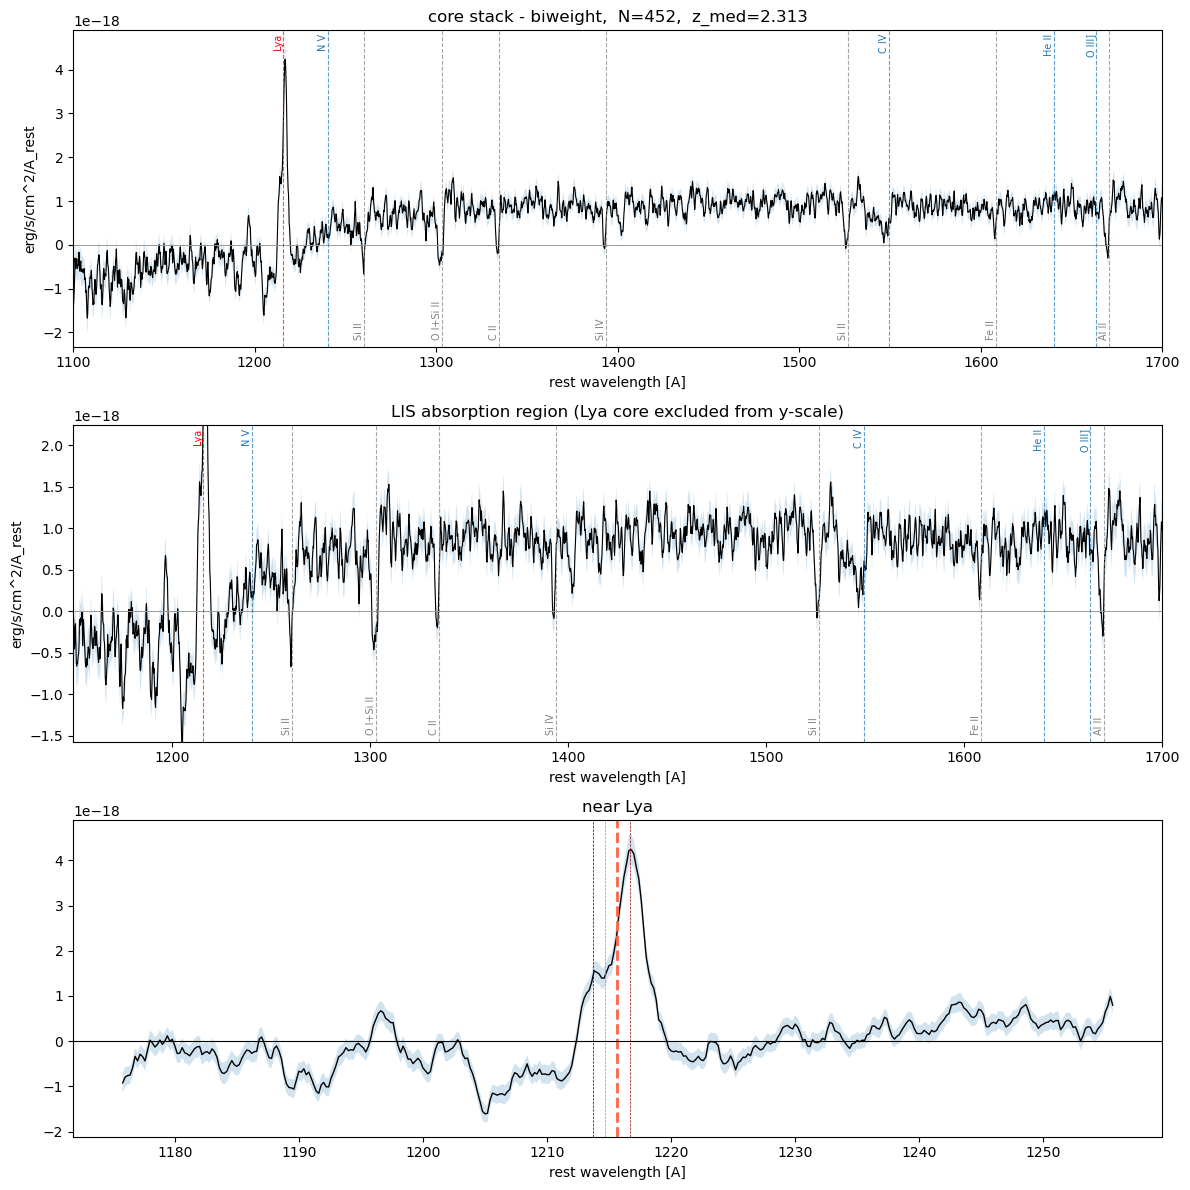

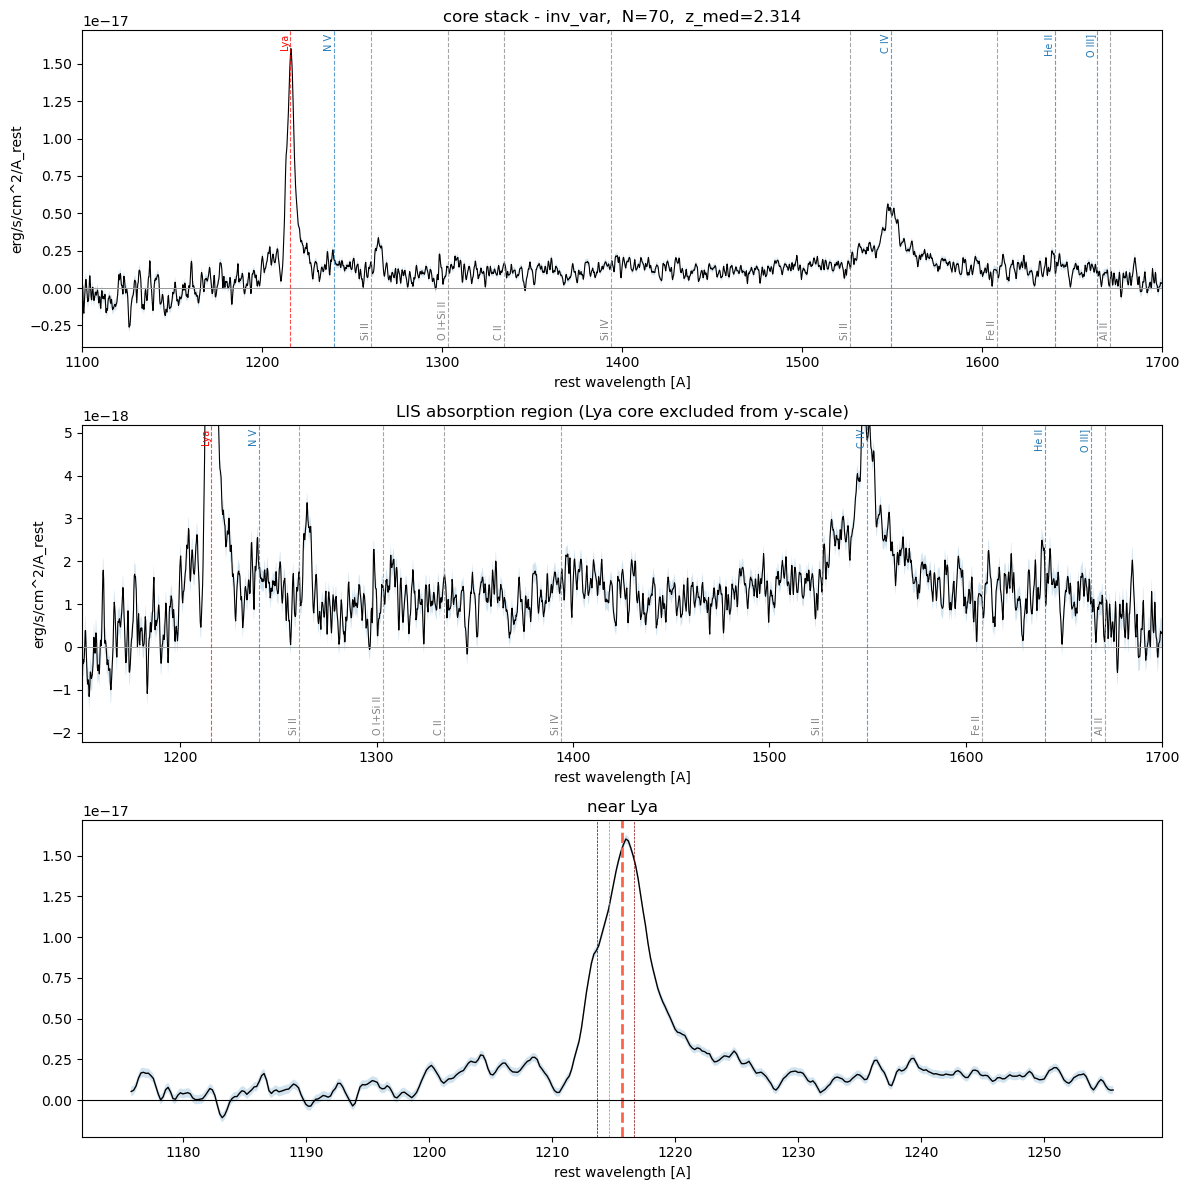

In [11]:
plotting.plot_core_stack(stack_gal, method="biweight")
plotting.plot_core_stack(stack_agn, method="inv_var")

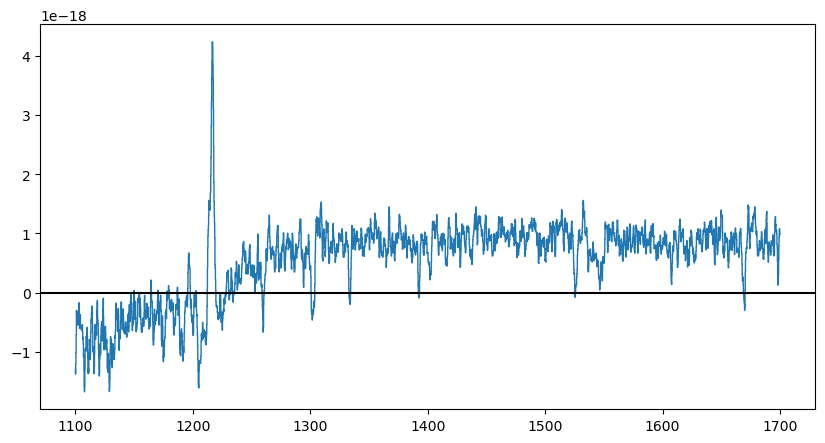

In [36]:
plt.figure(figsize=(10, 5))
plt.step(stack_gal['rest_wave'], stack_gal['stacks']['biweight']['flux'], lw=1)
plt.axhline(0, c='k')
# plt.axvline(1526.71, lw=1)
# plt.axvline(1526.00, lw=1)
# plt.xlim(1500, 1550)
# plt.axvline(1260.42, lw=1)
# plt.axvline(1260.00, lw=1)
# plt.xlim(1240, 1280)
# plt.axvline(1334.53, lw=1)
# plt.axvline(1334.00, lw=1)
# plt.xlim(1320, 1360)
# plt.axvline(1670.78, lw=1)
# plt.axvline(1670.00, lw=1)
# plt.xlim(1650, 1690)

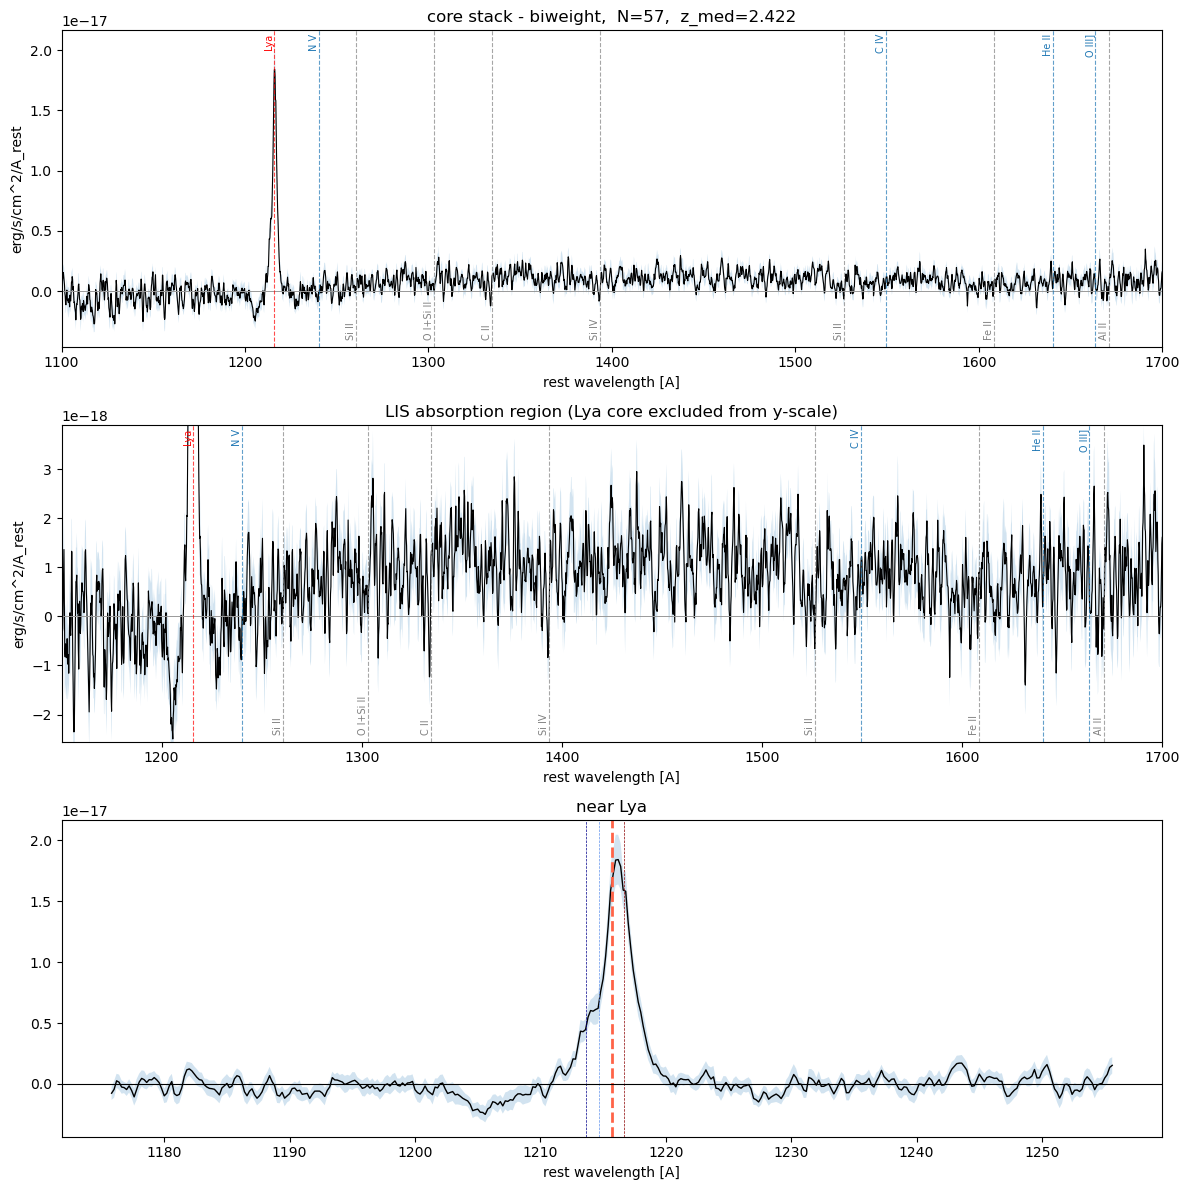

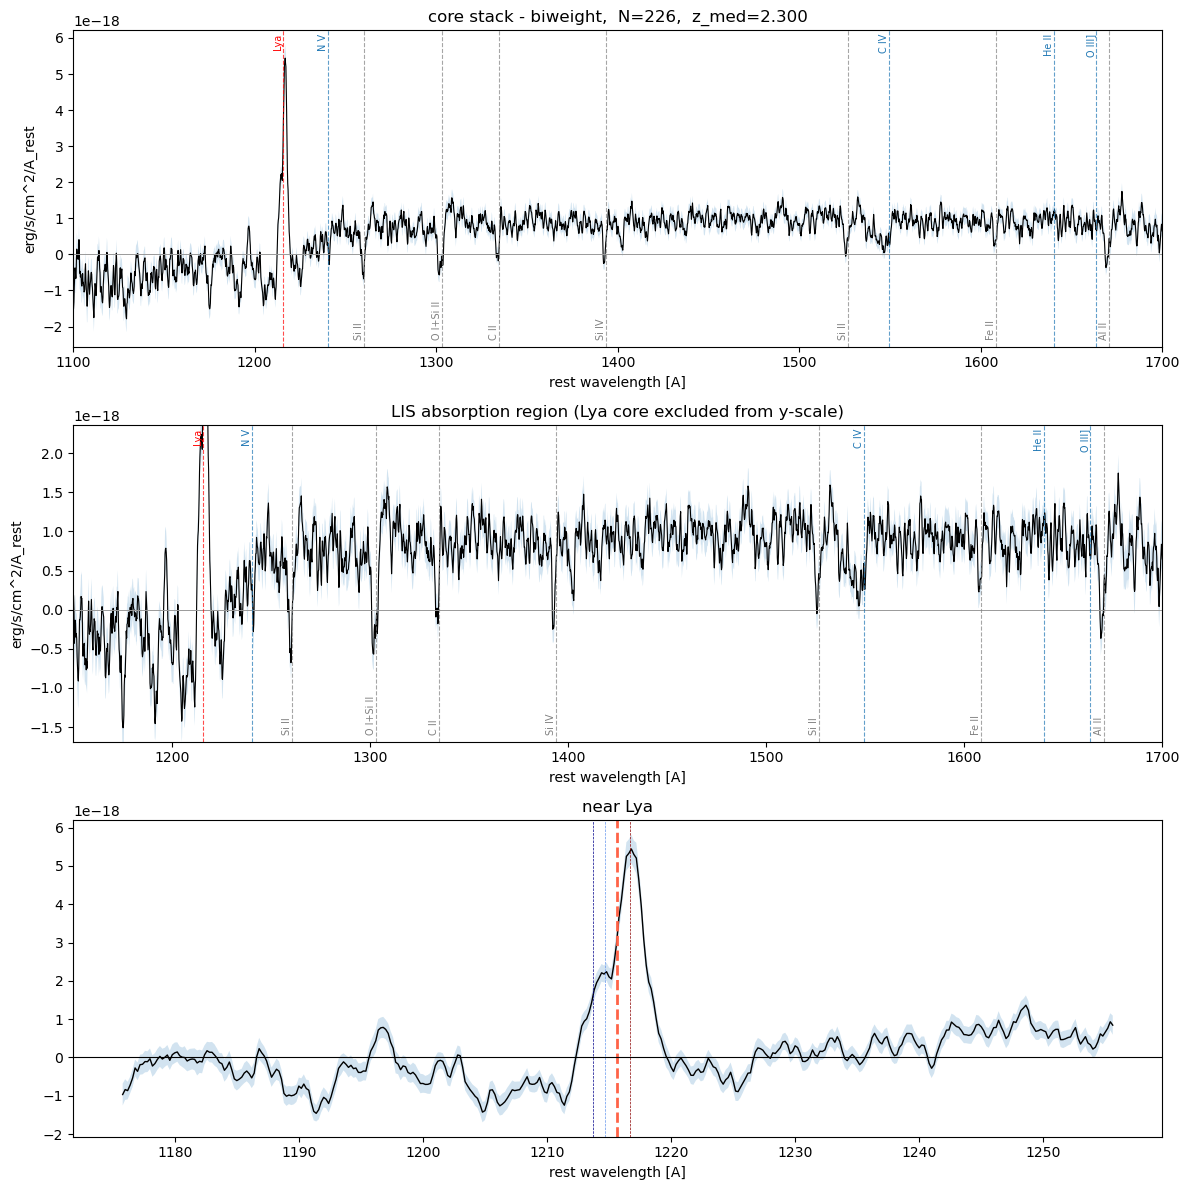

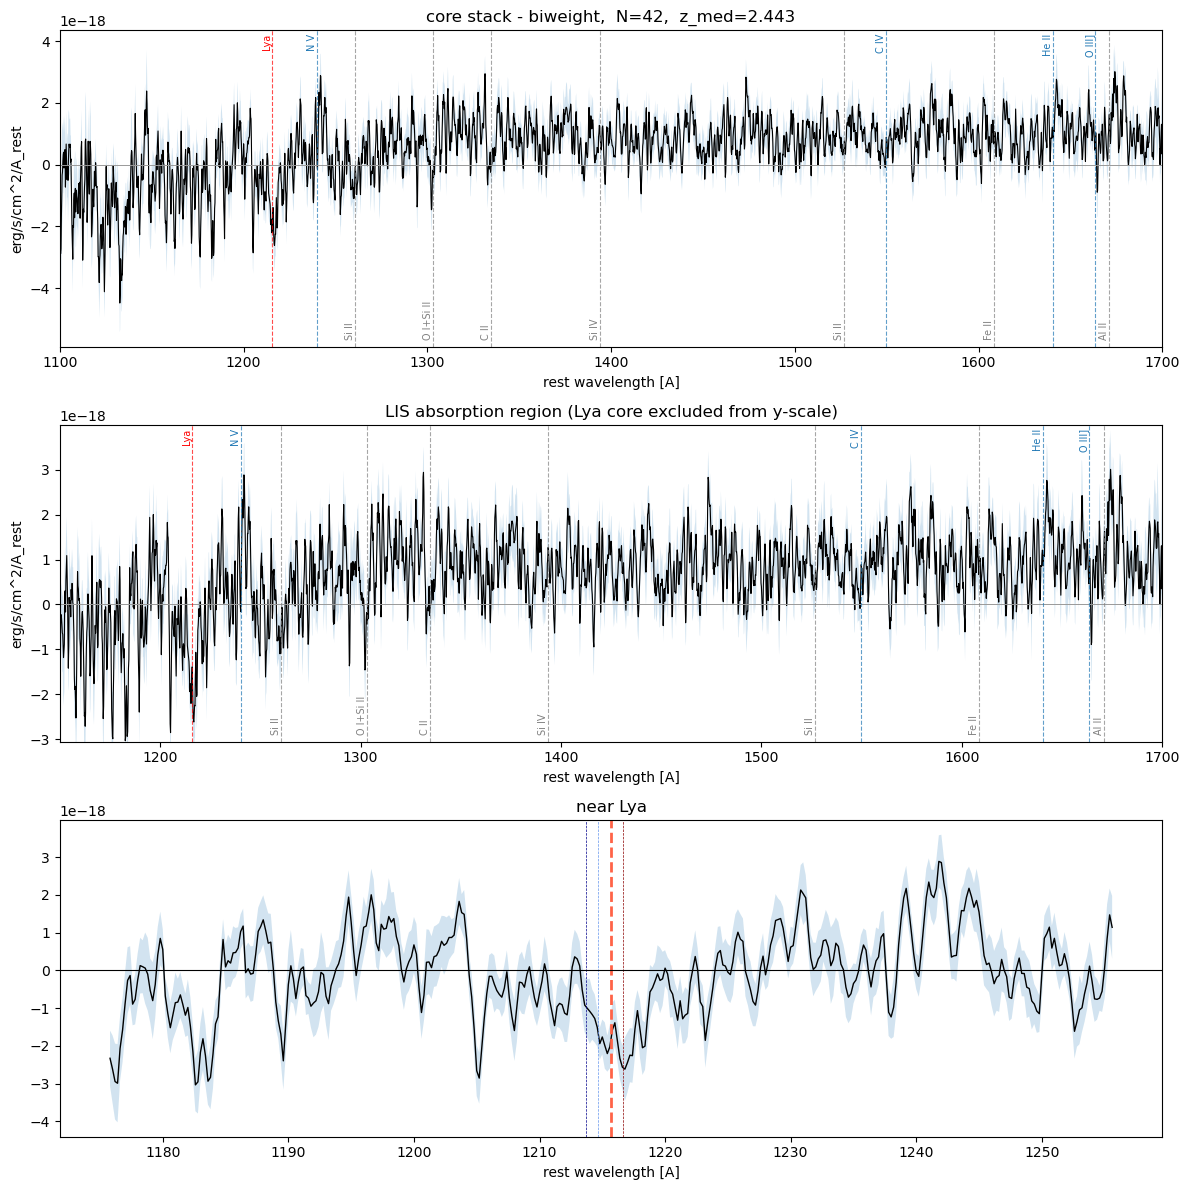

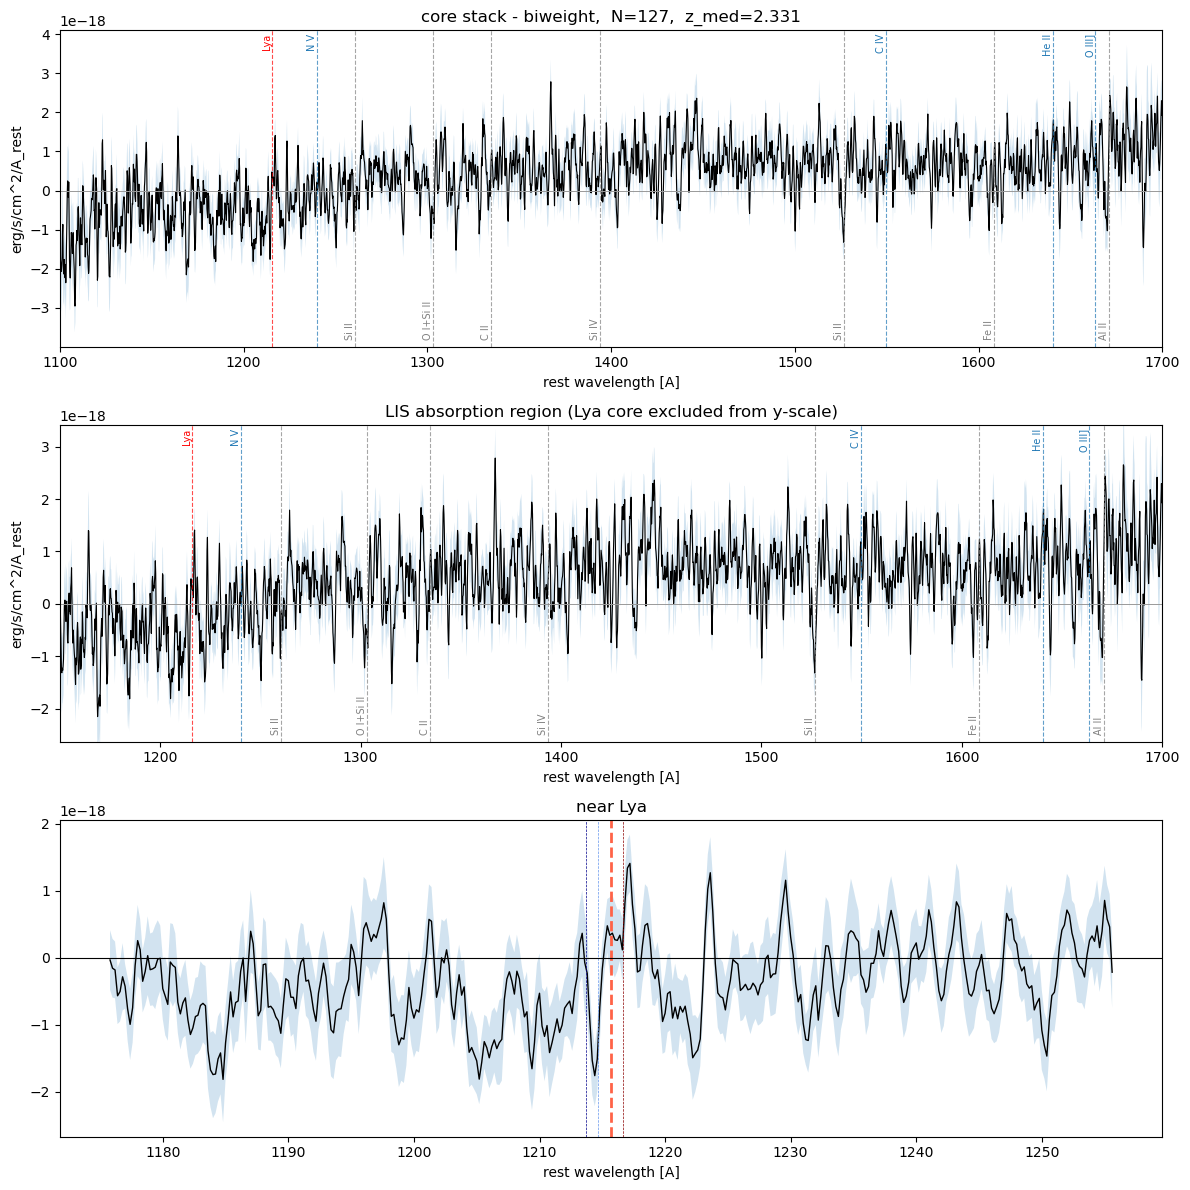

In [25]:
plotting.plot_core_stack(stack_lae, method="biweight")
plotting.plot_core_stack(stack_em, method="biweight")
plotting.plot_core_stack(stack_abs, method="biweight")
plotting.plot_core_stack(stack_null, method="biweight")

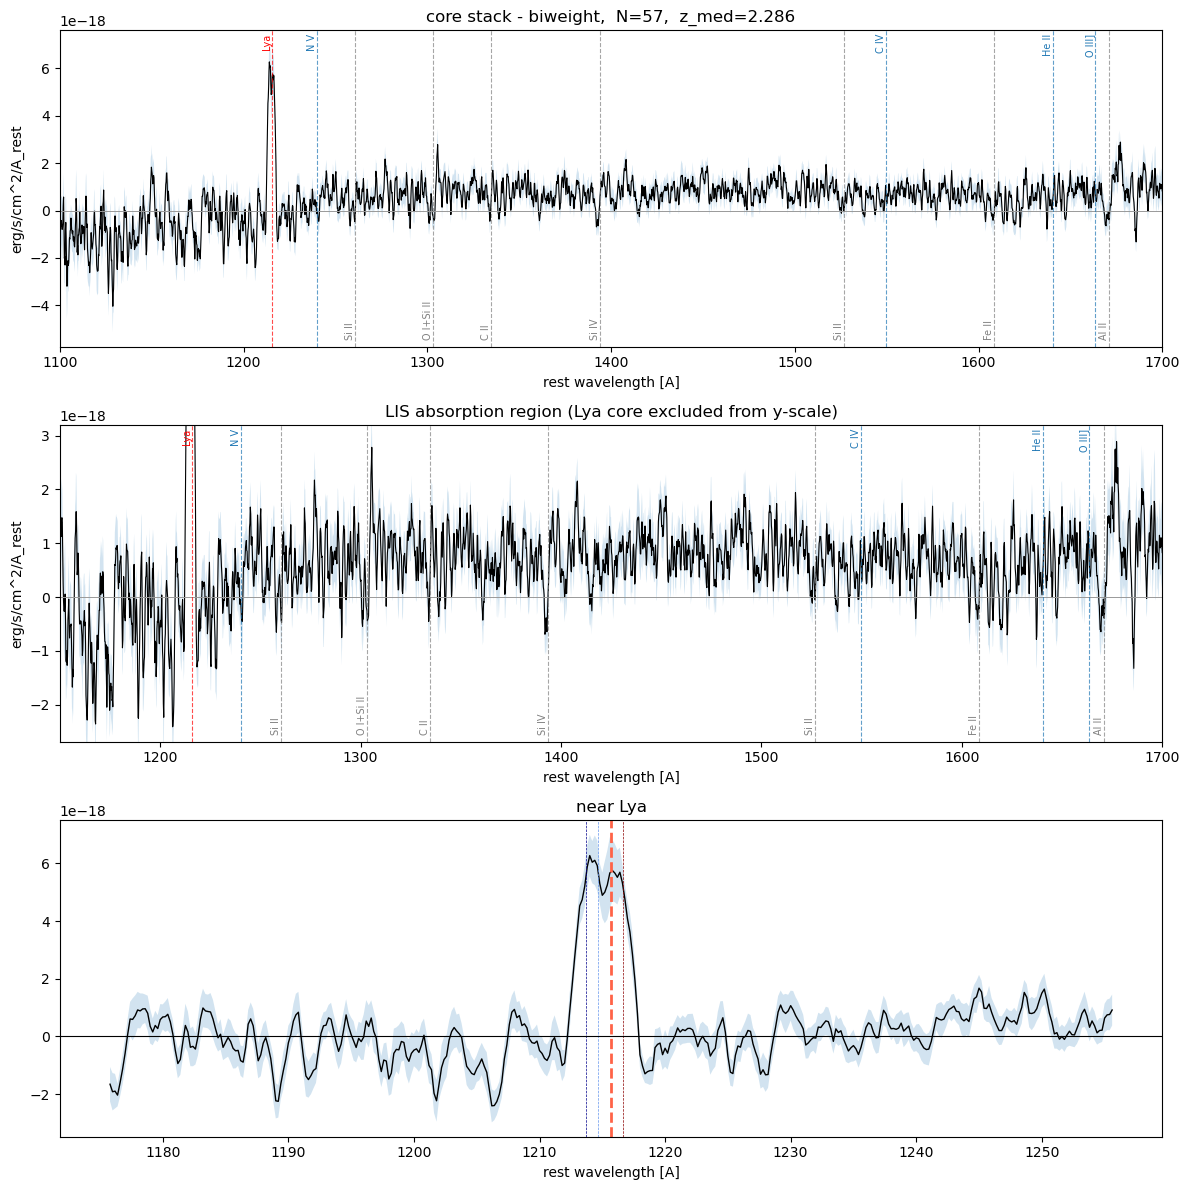

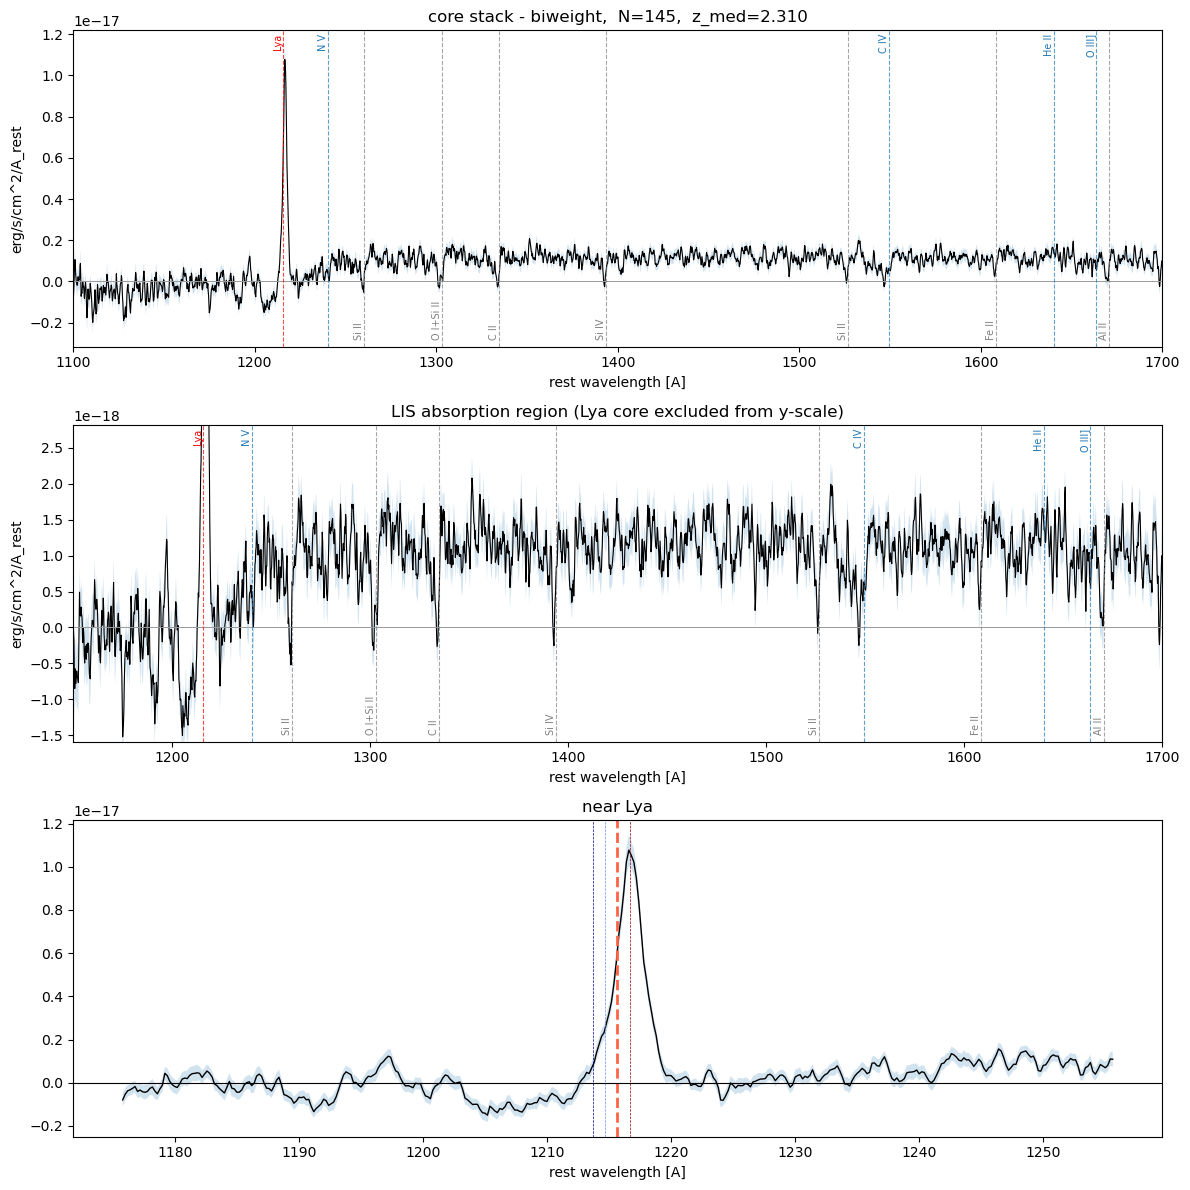

In [26]:
plotting.plot_core_stack(stack_blue, method="biweight")
plotting.plot_core_stack(stack_red, method="biweight")

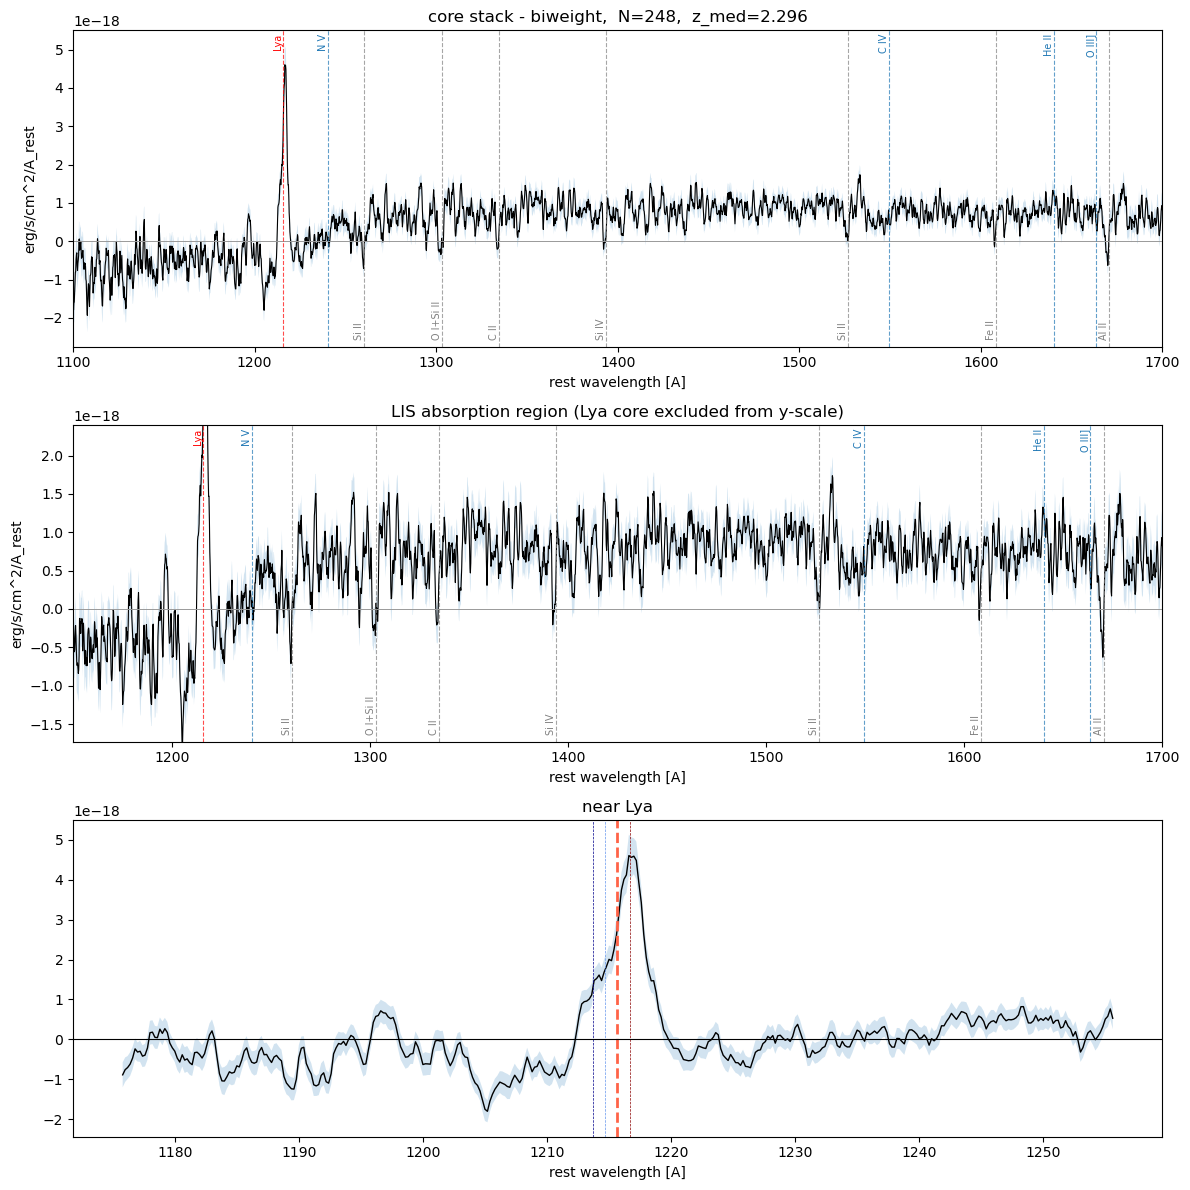

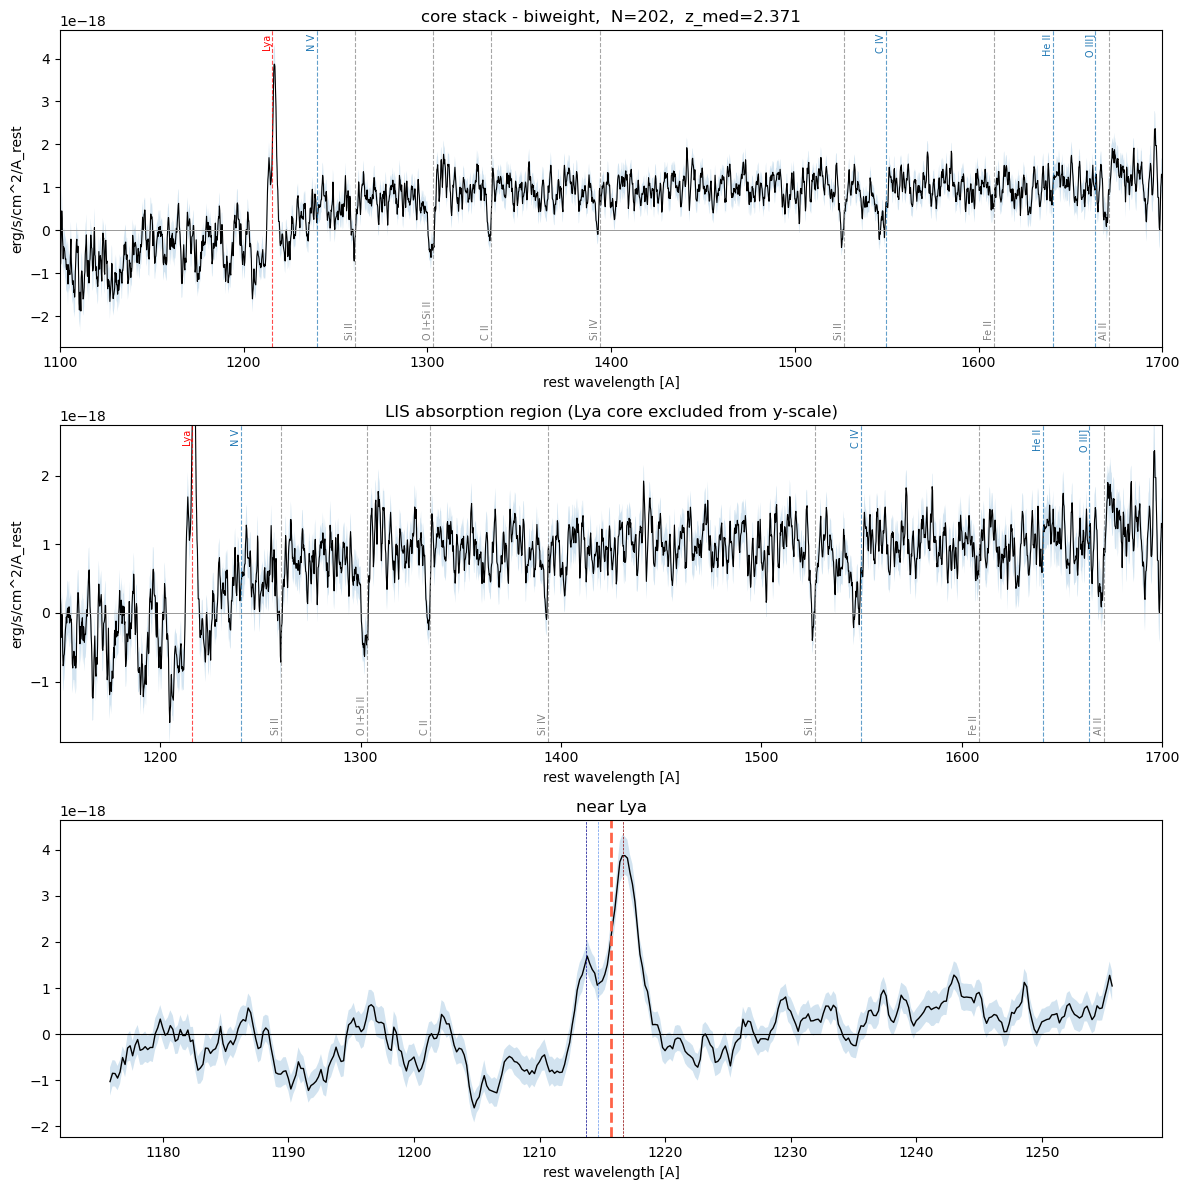

In [27]:
plotting.plot_core_stack(stack_lmass, method="biweight")
plotting.plot_core_stack(stack_hmass, method="biweight")

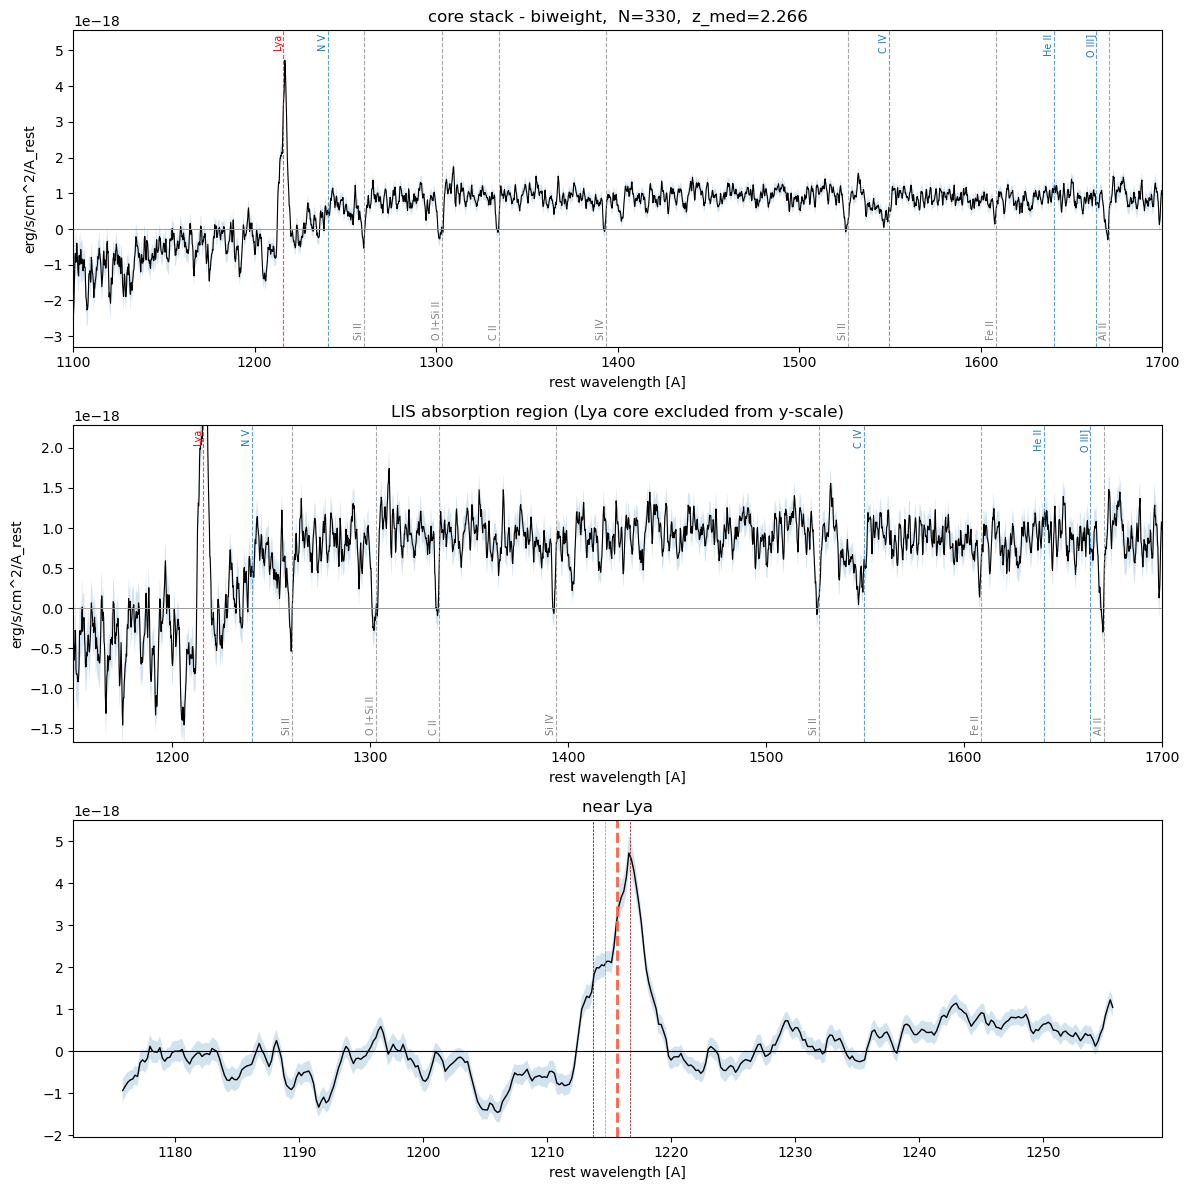

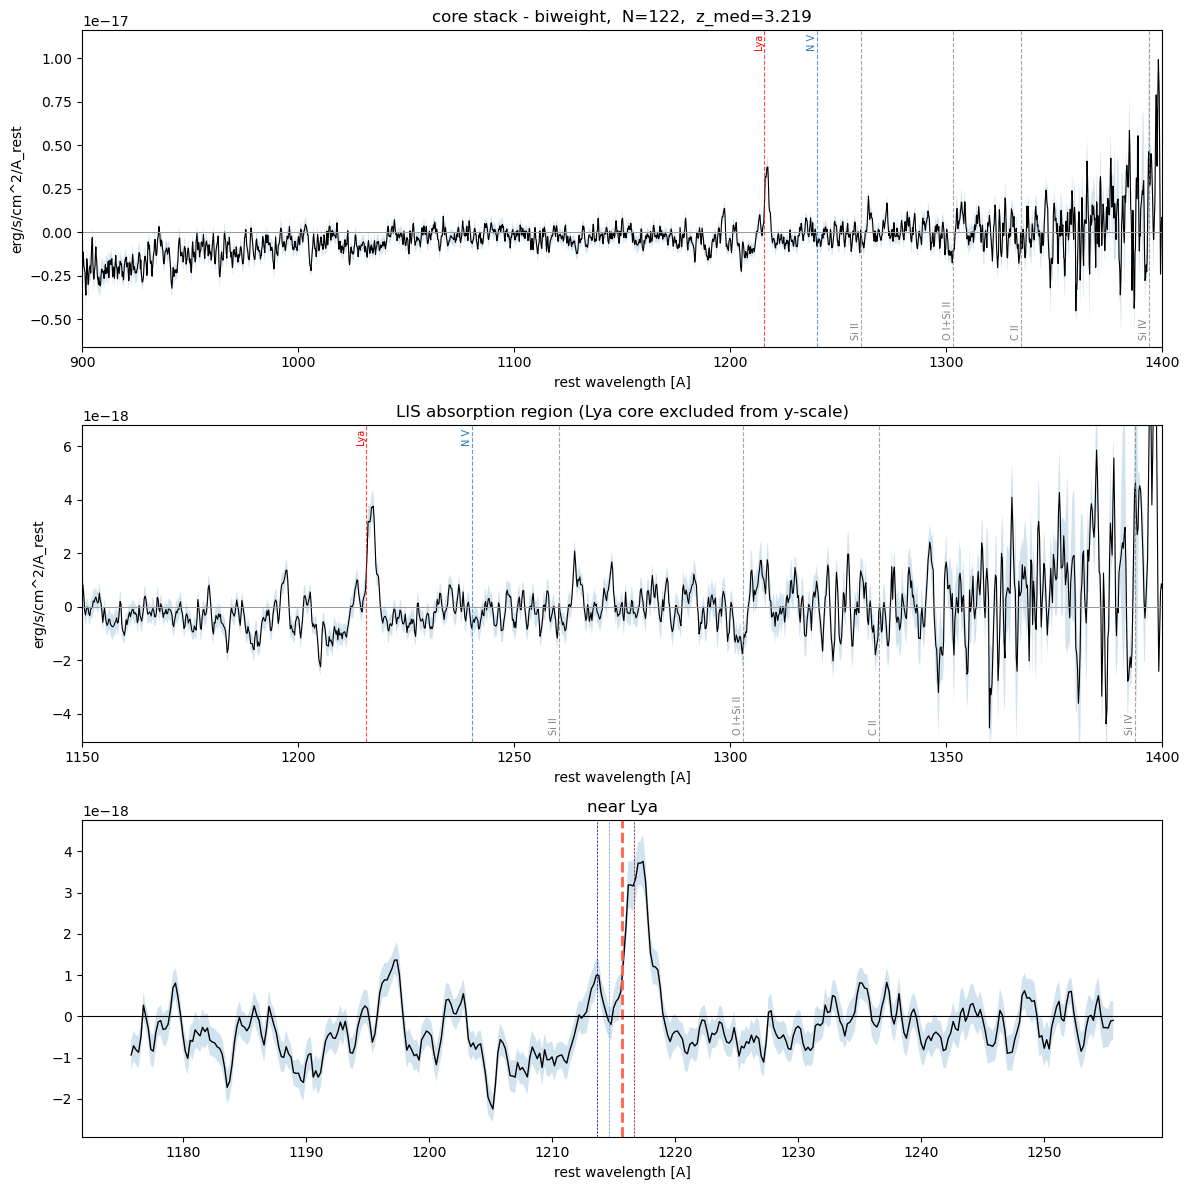

In [28]:
plotting.plot_core_stack(stack_lz, method="biweight")
plotting.plot_core_stack(stack_hz, method="biweight")

# Result Comparisons

In [29]:
# LAE folded into the label scheme (the high-EW emitter subset)
_LABELS  = ["LAE", "emitter", "absorber", "null"]
_LABEL_C = {"LAE": "gold", "emitter": "crimson", "absorber": "navy", "null": "0.7"}

def _R(x):
    """Accept a read_core_fits dict OR its 'results' sub-dict; return results."""
    if isinstance(x, dict) and isinstance(x.get("results"), dict):
        return x["results"]
    return x

def core_results_summary(prod, name=""):
    """Print and return success/label counts for one measurement run."""
    r = _R(prod); n = len(r["detected"])
    det = np.asarray(r["detected"], bool)
    gok = np.asarray(r.get("gauss_success", np.zeros(n, bool)), bool)
    lab = np.asarray(r.get("label", np.array(["null"] * n)), dtype=str)
    c = {"N": n, "detected": int(det.sum()), "gauss_ok": int(gok.sum())}
    for k in _LABELS:
        c[k] = int((lab == k).sum())
    tag = f"[{name}] " if name else ""
    print(f"{tag}N={c['N']}  detected={c['detected']} ({100*c['detected']/max(n,1):.0f}%)  "
          f"gauss_ok={c['gauss_ok']}  |  LAE={c['LAE']} emitter={c['emitter']} "
          f"absorber={c['absorber']} null={c['null']}")
    return c

def plot_core_diagnostics(prod, name="", bins=30):
    """One-dataset overview: S/N, v_offset, flux, f_esc histograms + success/label counts."""
    r = _R(prod); n = len(r["detected"])
    det = np.asarray(r["detected"], bool)
    gok = np.asarray(r.get("gauss_success", np.zeros(n, bool)), bool)
    lab = np.asarray(r.get("label", np.array(["null"] * n)), str)
    sn  = np.asarray(r["sn_mf"], float); vo = np.asarray(r["v_offset"], float)
    fmf = np.asarray(r["flux_mf"], float); thr = r.get("detect_snr", None)

    fig, ax = plt.subplots(2, 3, figsize=(16, 9))
    fig.suptitle(f"core diagnostics{(' - ' + name) if name else ''}  (N={n})", fontsize=13)

    a = ax[0, 0]; s = sn[np.isfinite(sn)]
    a.hist(s, bins=bins, color="0.6")
    if thr is not None:
        a.axvline(thr, color="r", ls="--", lw=1.2, label=f"detect S/N={thr:g}"); a.legend(fontsize=8)
    a.set_xlabel("sn_mf"); a.set_ylabel("N"); a.set_title("matched-filter S/N")

    a = ax[0, 1]; v = vo[gok & np.isfinite(vo)]
    a.hist(v, bins=bins, color="steelblue"); a.axvline(0, color="0.4", lw=0.8)
    if v.size:
        a.axvline(np.median(v), color="darkred", ls="--", lw=1.2,
                  label=f"median={np.median(v):.0f}"); a.legend(fontsize=8)
    a.set_xlabel("v_offset [km/s]"); a.set_title(f"Lya velocity offset (gauss_ok N={v.size})")

    a = ax[0, 2]; fd = fmf[det & np.isfinite(fmf)]
    a.hist(fd, bins=bins, color="seagreen"); a.axvline(0, color="0.4", lw=0.8)
    a.set_xlabel("flux_mf (detections)"); a.set_title("matched-filter flux (detected)")

    a = ax[1, 0]
    if "fesc" in r:
        fe = np.asarray(r["fesc"], float); fe = fe[np.isfinite(fe) & (fe > 0)]
        if fe.size:
            a.hist(np.log10(fe), bins=bins, color="indigo")
            a.set_xlabel("log10 f_esc"); a.set_title(f"escape fraction (N={fe.size})")
        else:
            a.axis("off"); a.text(0.5, 0.5, "no positive f_esc", ha="center", va="center")
    else:
        a.axis("off"); a.text(0.5, 0.5, "no fesc (escape=False)", ha="center", va="center")

    a = ax[1, 1]
    vals = [int(det.sum()), int((~det).sum()), int(gok.sum())]
    a.bar(["detected", "non-det", "gauss_ok"], vals, color=["seagreen", "0.7", "steelblue"])
    for i, vv in enumerate(vals): a.text(i, vv, str(vv), ha="center", va="bottom", fontsize=9)
    a.set_title("detection / fit success"); a.set_ylabel("N")

    a = ax[1, 2]
    vals = [int((lab == k).sum()) for k in _LABELS]
    a.bar(_LABELS, vals, color=[_LABEL_C[k] for k in _LABELS])
    for i, vv in enumerate(vals):
        a.text(i, vv, str(vv), ha="center", va="bottom", fontsize=9)
    a.set_title("classification label"); a.set_ylabel("N")
    plt.tight_layout(); plt.show()


def plot_flux_estimators(prod, name="", restrict="detected", ratio_clip=(-2, 4)):
    """Compare the three Lya fluxes: flux_mf (matched filter), flux_a (Gaussian
    +/-2sigma), flux_b (window). Top: pairwise scatter w/ 1:1; bottom: y/x ratios."""
    r = _R(prod); n = len(r["flux_mf"])
    det = np.asarray(r["detected"], bool)
    mf = np.asarray(r["flux_mf"], float); fa = np.asarray(r["flux_a"], float)
    fb = np.asarray(r["flux_b"], float)
    base = det if restrict == "detected" else np.ones(n, bool)
    pairs = [(mf, fa, "flux_mf", "flux_a (Gaussian)"),
             (mf, fb, "flux_mf", "flux_b (window)"),
             (fa, fb, "flux_a (Gaussian)", "flux_b (window)")]

    fig, ax = plt.subplots(2, 3, figsize=(16, 10))
    sub = "detections" if restrict == "detected" else "all"
    fig.suptitle(f"flux estimator comparison{(' - ' + name) if name else ''}  ({sub})", fontsize=13)

    for j, (x, y, xl, yl) in enumerate(pairs):
        m = base & np.isfinite(x) & np.isfinite(y)
        with np.errstate(invalid="ignore", divide="ignore"):
            ratio = (y[m] / x[m])
        ratio = ratio[np.isfinite(ratio)]; med = np.median(ratio) if ratio.size else np.nan

        a = ax[0, j]; a.scatter(x[m], y[m], s=12, alpha=0.5, color="steelblue")
        if m.sum():
            lim = [np.nanmin([x[m].min(), y[m].min()]), np.nanmax([x[m].max(), y[m].max()])]
            a.plot(lim, lim, "k--", lw=0.8)
        a.set_xlabel(xl); a.set_ylabel(yl)
        a.set_title(f"{yl} vs {xl}\nN={int(m.sum())}, median y/x={med:.2f}", fontsize=9)

        b = ax[1, j]
        if ratio.size:
            rc = ratio[(ratio > ratio_clip[0]) & (ratio < ratio_clip[1])]
            b.hist(rc, bins=30, color="0.6")
            b.axvline(1.0, color="r", ls="--", lw=1.2)
            b.axvline(med, color="darkred", ls=":", lw=1.2, label=f"median={med:.2f}"); b.legend(fontsize=8)
        b.set_xlabel(f"{yl} / {xl}"); b.set_ylabel("N")
    plt.tight_layout(); plt.show()


def compare_core_versions(prod_a, prod_b, labels=("v1", "v2"), bins=30):
    """Compare two measurement versions (e.g. before/after a re-measure). If they
    share galaxy order (same extraction) it also shows per-galaxy deltas."""
    ra, rb = _R(prod_a), _R(prod_b)
    na, nb = len(ra["detected"]), len(rb["detected"]); la, lb = labels
    print(f"=== {la} vs {lb} ===")
    ca = core_results_summary(ra, la); cb = core_results_summary(rb, lb)
    aligned = (na == nb)
    if not aligned:
        print(f"\n[warn] different N ({na} vs {nb}); distributions only, no per-galaxy deltas.")

    fig, ax = plt.subplots(2, 3, figsize=(16, 9))
    fig.suptitle(f"version comparison: {la} vs {lb}", fontsize=13)

    a = ax[0, 0]
    cats = ["detected", "gauss_ok"] + _LABELS      # was [..., "emitter","absorber","null"]
    va = [ca[k] for k in cats]; vb = [cb[k] for k in cats]
    x = np.arange(len(cats)); w = 0.4
    a.bar(x - w / 2, va, w, label=la); a.bar(x + w / 2, vb, w, label=lb)
    a.set_xticks(x); a.set_xticklabels(cats, rotation=30, ha="right")
    a.legend(fontsize=8); a.set_title("counts"); a.set_ylabel("N")

    def _ov(a, key, xlabel, ma=None, mb=None):
        xa = np.asarray(ra[key], float); xb = np.asarray(rb[key], float)
        if ma is not None: xa = xa[ma]
        if mb is not None: xb = xb[mb]
        xa = xa[np.isfinite(xa)]; xb = xb[np.isfinite(xb)]
        rng = (min(xa.min(), xb.min()), max(xa.max(), xb.max())) if xa.size and xb.size else None
        a.hist(xa, bins=bins, range=rng, histtype="step", lw=1.5, label=la)
        a.hist(xb, bins=bins, range=rng, histtype="step", lw=1.5, label=lb)
        a.legend(fontsize=8); a.set_xlabel(xlabel); a.set_ylabel("N")

    _ov(ax[0, 1], "sn_mf", "sn_mf"); ax[0, 1].set_title("matched-filter S/N")
    ga = np.asarray(ra.get("gauss_success", np.zeros(na, bool)), bool)
    gb = np.asarray(rb.get("gauss_success", np.zeros(nb, bool)), bool)
    _ov(ax[0, 2], "v_offset", "v_offset [km/s]", ma=ga, mb=gb)
    ax[0, 2].set_title("v_offset (gauss_ok)")

    if aligned:
        d_sn = np.asarray(rb["sn_mf"], float) - np.asarray(ra["sn_mf"], float)
        d_v  = np.asarray(rb["v_offset"], float) - np.asarray(ra["v_offset"], float)
        a = ax[1, 0]; d = d_sn[np.isfinite(d_sn)]
        a.hist(d, bins=bins, color="0.6"); a.axvline(0, color="r", ls="--")
        a.set_title(f"Δ sn_mf ({lb}-{la})"); a.set_xlabel("Δ sn_mf"); a.set_ylabel("N")
        a = ax[1, 1]; d = d_v[np.isfinite(d_v)]
        a.hist(d, bins=bins, color="0.6"); a.axvline(0, color="r", ls="--")
        a.set_title("Δ v_offset"); a.set_xlabel("Δ v_offset [km/s]"); a.set_ylabel("N")
        a = ax[1, 2]
        xa = np.asarray(ra["v_offset"], float); xb = np.asarray(rb["v_offset"], float)
        m = np.isfinite(xa) & np.isfinite(xb)
        a.scatter(xa[m], xb[m], s=12, alpha=0.5)
        if m.sum():
            lim = [np.nanmin([xa[m].min(), xb[m].min()]), np.nanmax([xa[m].max(), xb[m].max()])]
            a.plot(lim, lim, "k--", lw=0.8)
        a.set_xlabel(f"v_offset {la}"); a.set_ylabel(f"v_offset {lb}"); a.set_title("v_offset 1:1")
        da = np.asarray(ra["detected"], bool); db = np.asarray(rb["detected"], bool)
        print(f"\nper-galaxy detection change: +{int((~da & db).sum())} gained, "
              f"-{int((da & ~db).sum())} lost  (net {cb['detected'] - ca['detected']:+d})")
    else:
        for a in (ax[1, 0], ax[1, 1], ax[1, 2]): a.axis("off")
        ax[1, 0].text(0.5, 0.5, "per-galaxy deltas\nunavailable (N differs)", ha="center", va="center")
    plt.tight_layout(); plt.show()

[BOTH] N=522  detected=295 (57%)  gauss_ok=232  |  LAE=79 emitter=247 absorber=49 null=147


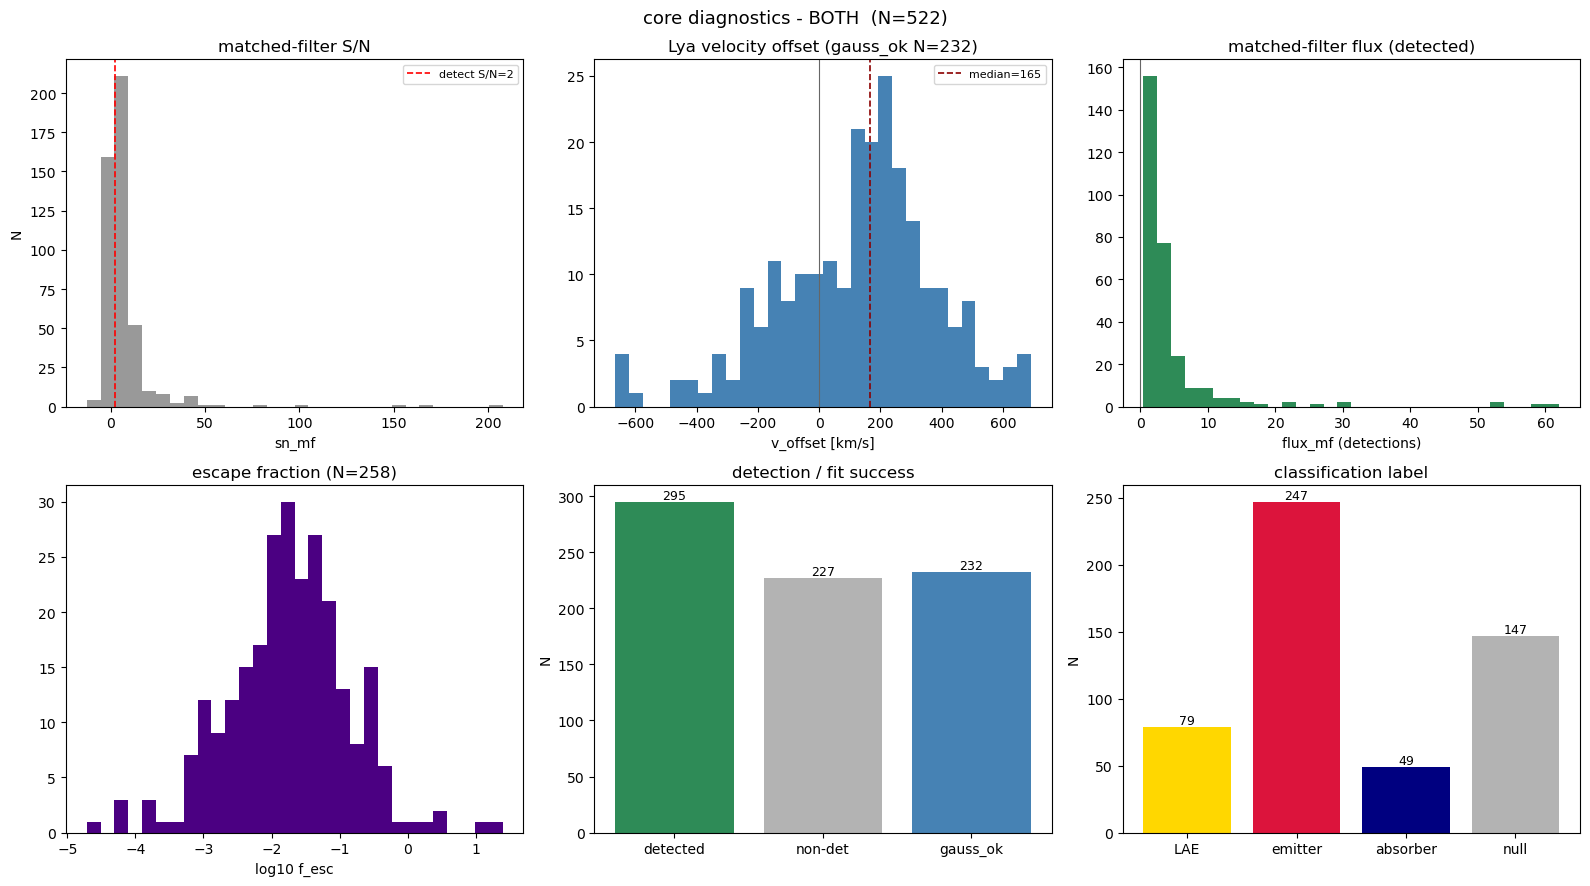

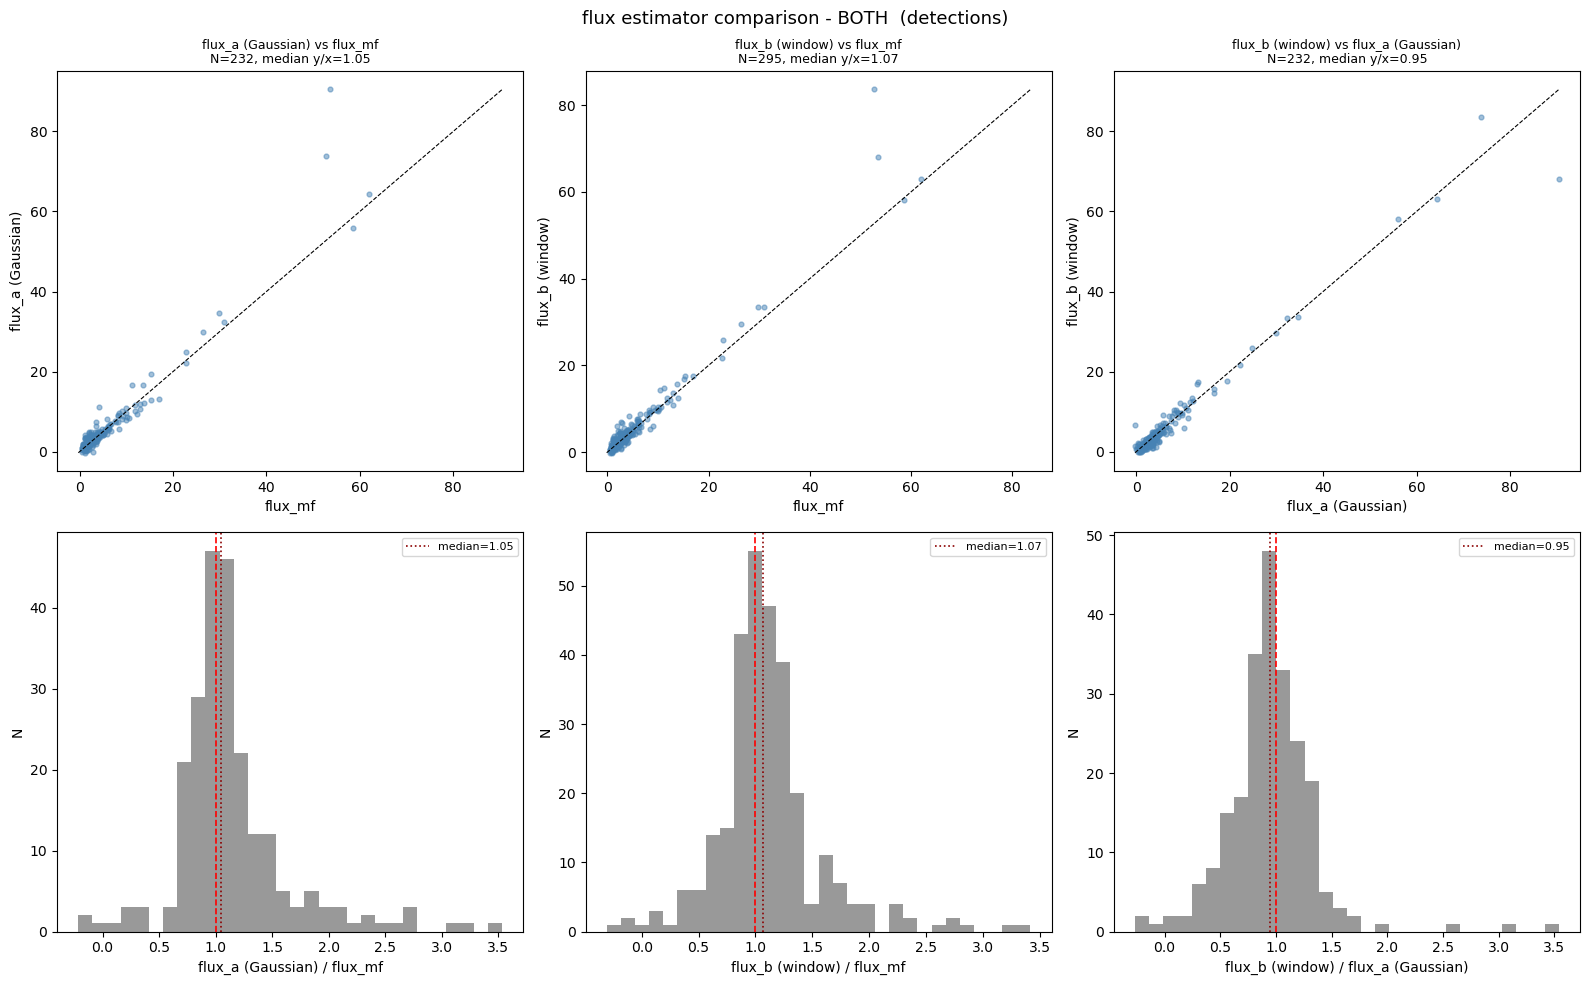

In [30]:
core_results_summary(prod, "BOTH")          # one-line counts
plot_core_diagnostics(prod, "BOTH")         # histograms + success/label bars
plot_flux_estimators(prod, "BOTH")          # mf vs Gaussian vs window, + ratio hists

=== B vs MF ===
[B] N=522  detected=245 (47%)  gauss_ok=201  |  LAE=81 emitter=199 absorber=39 null=203
[MF] N=522  detected=295 (57%)  gauss_ok=232  |  LAE=79 emitter=247 absorber=49 null=147

per-galaxy detection change: +51 gained, -1 lost  (net +50)


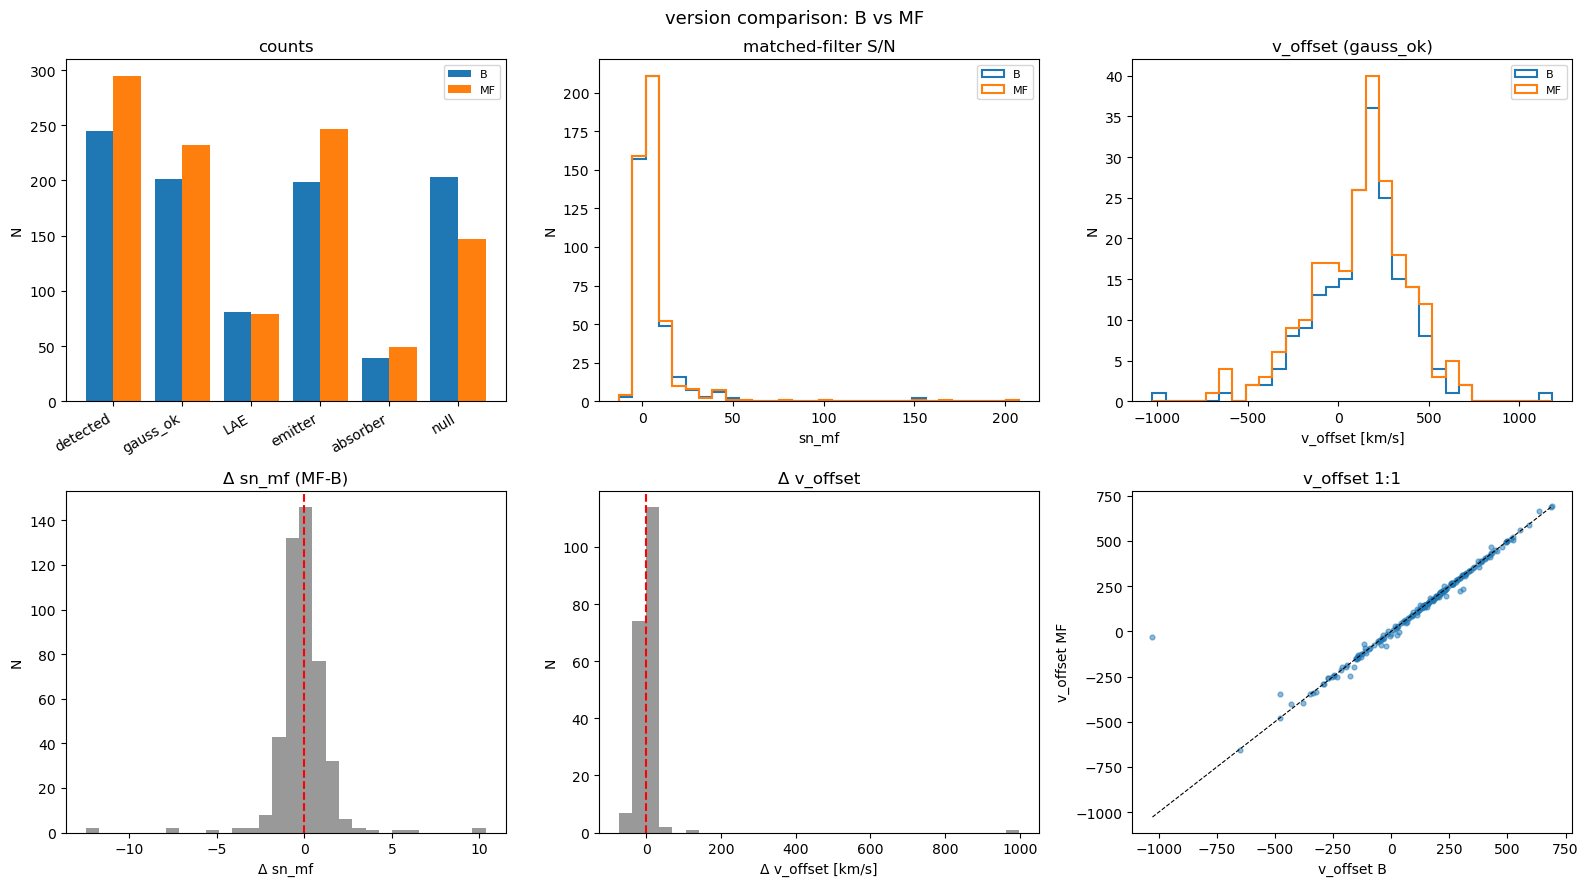

In [32]:
LyaB_e = core.read_core_fits("outputs_core/7-5-26-core_extraction_egs_B.fits")
LyaB_c = core.read_core_fits("outputs_core/7-5-26-core_extraction_cosmos_B.fits")
LyaB = stack.concat_core_prods(LyaB_e, LyaB_c)

LyaMF_e = core.read_core_fits("outputs_core/7-5-26-core_extraction_egs_MF.fits")
LyaMF_c = core.read_core_fits("outputs_core/7-5-26-core_extraction_cosmos_MF.fits")
LyaMF = stack.concat_core_prods(LyaMF_e, LyaMF_c)

compare_core_versions(LyaB, LyaMF, labels=("B", "MF"))

# Further Investigation in Results

In [72]:
mask_sn = prod['results']['sn_mf'] > 30
print(np.sum(mask_sn))

18


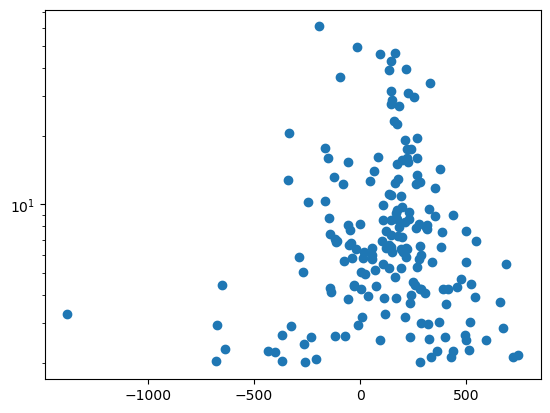

In [65]:
plt.scatter(prod['results']['v_offset'][mask_clean], prod['results']['sn_mf'][mask_clean])
plt.yscale('log')

In [74]:
ids = [
    1606, 5095, 5130, 5224, 6743, 8388, 10769, 11487, 12302,
    12615, 13429, 14596, 15359, 17664, 17754, 19082, 21290, 21492, 22995,
    24192, 26009, 26304, 30014, 30274, 32856, 33691, 38195]

In [79]:
prod['catalog'][np.isin(prod['catalog']['ID'], ids)]

INDEX,FIELD,CATALOG,ID,ID_V21,ID_V41,MASKNAME,SLITOBJNAME,RA,DEC,z,Z_QUAL,HA_FLUX,HA_FLUX_ERR,HA_FWHM,HA_FWHM_ERR,HB_FLUX,HB_FLUX_ERR,HB_FWHM,HB_FWHM_ERR,HG_FLUX,HG_FLUX_ERR,HG_FWHM,HG_FWHM_ERR,HD_FLUX,HD_FLUX_ERR,HD_FWHM,HD_FWHM_ERR,OII3727_FLUX,OII3727_FLUX_ERR,OII3727_FWHM,OII3727_FWHM_ERR,OII3730_FLUX,OII3730_FLUX_ERR,OII3730_FWHM,OII3730_FWHM_ERR,OIII4364_FLUX,OIII4364_FLUX_ERR,OIII4364_FWHM,OIII4364_FWHM_ERR,OIII4960_FLUX,OIII4960_FLUX_ERR,OIII4960_FWHM,OIII4960_FWHM_ERR,OIII5008_FLUX,OIII5008_FLUX_ERR,OIII5008_FWHM,OIII5008_FWHM_ERR,OI6302_FLUX,OI6302_FLUX_ERR,OI6302_FWHM,OI6302_FWHM_ERR,NII6550_FLUX,NII6550_FLUX_ERR,NII6550_FWHM,NII6550_FWHM_ERR,NII6585_FLUX,NII6585_FLUX_ERR,NII6585_FWHM,NII6585_FWHM_ERR,SII6718_FLUX,SII6718_FLUX_ERR,SII6718_FWHM,SII6718_FWHM_ERR,SII6733_FLUX,SII6733_FLUX_ERR,SII6733_FWHM,SII6733_FWHM_ERR,NEIII3870_FLUX,NEIII3870_FLUX_ERR,NEIII3870_FWHM,NEIII3870_FWHM_ERR,NEIII3969_FLUX,NEIII3969_FLUX_ERR,NEIII3969_FWHM,NEIII3969_FWHM_ERR,NIIHA,NIIHA_ERR,MASS_50,MASS_16,MASS_84,SFR_50,SFR_16,SFR_84,SSFR_50,SSFR_16,SSFR_84,AV_50,AV_16,AV_84,AGE_50,AGE_16,AGE_84,TAU_50,TAU_16,TAU_84,CHI2,ZFAST,EBV_STAR_16,EBV_STAR_50,EBV_STAR_84,HA_SN,HA_FLAG,HB_SN,HB_FLAG,HG_SN,HG_FLAG,HD_SN,HD_FLAG,OII3727_SN,OII3727_FLAG,OII3730_SN,OII3730_FLAG,OIII4364_SN,OIII4364_FLAG,OIII4960_SN,OIII4960_FLAG,OIII5008_SN,OIII5008_FLAG,OI6302_SN,OI6302_FLAG,NII6550_SN,NII6550_FLAG,NII6585_SN,NII6585_FLAG,SII6718_SN,SII6718_FLAG,SII6733_SN,SII6733_FLAG,NEIII3870_SN,NEIII3870_FLAG,NEIII3969_SN,NEIII3969_FLAG,O3,O3_ERR,O32,O32_ERR,EBV_NEB_16,EBV_NEB_50,EBV_NEB_84,FLUX_RADIUS,A_IMAGE,B_IMAGE,THETA_J2000,KRON_RADIUS,FWHM_IMAGE,CLASS_STAR,F_F160W,E_F160W,F_F814W,E_F814W,F_F606W,E_F606W,F_G,E_G,F_R,E_R,F_V,E_V,F_IRAC1,E_IRAC1,IRAC1_CONTAM,F_IRAC2,E_IRAC2,IRAC2_CONTAM,F_IRAC3,E_IRAC3,IRAC3_CONTAM,F_IRAC4,E_IRAC4,IRAC4_CONTAM,USE_PHOT,STAR_FLAG,PHOT_FLAGS,Z_SPEC,TOT_COR,SKELTON_MATCH,BA,INCL_DEG,MAG_G,MAG_R,MAG_V,MAG_F606W,MAG_F814W,MAG_F160W,GR_COLOR,Z_SECURE,Z_INWINDOW,BEST_LINE_SN,LINE_SN_OK,COORDS_OK,SAMPLE,HAS_DUP_0p5AS,DUP_DROP,BLEND_DROP,BLEND_MERGE,KEEP,XRAY_MATCH,XRAY_SEP_AS,XRAY_NAME,XRAY_FLUX_B,XRAY_SIG,AGN_XRAY,NIIHA_OK,BPT_O3HB,BPT_N2HA,AGN_OPT_USABLE,AGN_OPT,DONLEY_X,DONLEY_Y,AGN_IR_USABLE,AGN_IR,AGN_FLAG,CLEAN,MEX_O3HB,AGN_MEX,MEX_INTERMED,AGN_MEX_USABLE,AGN_MEX_APPLIED,VALID,EBV
int64,str6,str6,int64,int64,int64,str7,int64,float64,float64,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,str2,float64,float64,float64,float64,float64,float64,float64,float64,float64,bool,bool,float64,bool,bool,bool,bool,bool,bool,bool,bool,bool,float64,str21,float64,float64,bool,bool,float64,float64,bool,bool,float64,float64,bool,bool,bool,bool,float64,bool,bool,bool,bool,bool,float64
282,AEGIS,MOSDEF,30014,10942,30014,ae2_04,30014,214.83912

In [73]:
prod['catalog'][mask_clean & mask_sn]

INDEX,FIELD,CATALOG,ID,ID_V21,ID_V41,MASKNAME,SLITOBJNAME,RA,DEC,z,Z_QUAL,HA_FLUX,HA_FLUX_ERR,HA_FWHM,HA_FWHM_ERR,HB_FLUX,HB_FLUX_ERR,HB_FWHM,HB_FWHM_ERR,HG_FLUX,HG_FLUX_ERR,HG_FWHM,HG_FWHM_ERR,HD_FLUX,HD_FLUX_ERR,HD_FWHM,HD_FWHM_ERR,OII3727_FLUX,OII3727_FLUX_ERR,OII3727_FWHM,OII3727_FWHM_ERR,OII3730_FLUX,OII3730_FLUX_ERR,OII3730_FWHM,OII3730_FWHM_ERR,OIII4364_FLUX,OIII4364_FLUX_ERR,OIII4364_FWHM,OIII4364_FWHM_ERR,OIII4960_FLUX,OIII4960_FLUX_ERR,OIII4960_FWHM,OIII4960_FWHM_ERR,OIII5008_FLUX,OIII5008_FLUX_ERR,OIII5008_FWHM,OIII5008_FWHM_ERR,OI6302_FLUX,OI6302_FLUX_ERR,OI6302_FWHM,OI6302_FWHM_ERR,NII6550_FLUX,NII6550_FLUX_ERR,NII6550_FWHM,NII6550_FWHM_ERR,NII6585_FLUX,NII6585_FLUX_ERR,NII6585_FWHM,NII6585_FWHM_ERR,SII6718_FLUX,SII6718_FLUX_ERR,SII6718_FWHM,SII6718_FWHM_ERR,SII6733_FLUX,SII6733_FLUX_ERR,SII6733_FWHM,SII6733_FWHM_ERR,NEIII3870_FLUX,NEIII3870_FLUX_ERR,NEIII3870_FWHM,NEIII3870_FWHM_ERR,NEIII3969_FLUX,NEIII3969_FLUX_ERR,NEIII3969_FWHM,NEIII3969_FWHM_ERR,NIIHA,NIIHA_ERR,MASS_50,MASS_16,MASS_84,SFR_50,SFR_16,SFR_84,SSFR_50,SSFR_16,SSFR_84,AV_50,AV_16,AV_84,AGE_50,AGE_16,AGE_84,TAU_50,TAU_16,TAU_84,CHI2,ZFAST,EBV_STAR_16,EBV_STAR_50,EBV_STAR_84,HA_SN,HA_FLAG,HB_SN,HB_FLAG,HG_SN,HG_FLAG,HD_SN,HD_FLAG,OII3727_SN,OII3727_FLAG,OII3730_SN,OII3730_FLAG,OIII4364_SN,OIII4364_FLAG,OIII4960_SN,OIII4960_FLAG,OIII5008_SN,OIII5008_FLAG,OI6302_SN,OI6302_FLAG,NII6550_SN,NII6550_FLAG,NII6585_SN,NII6585_FLAG,SII6718_SN,SII6718_FLAG,SII6733_SN,SII6733_FLAG,NEIII3870_SN,NEIII3870_FLAG,NEIII3969_SN,NEIII3969_FLAG,O3,O3_ERR,O32,O32_ERR,EBV_NEB_16,EBV_NEB_50,EBV_NEB_84,FLUX_RADIUS,A_IMAGE,B_IMAGE,THETA_J2000,KRON_RADIUS,FWHM_IMAGE,CLASS_STAR,F_F160W,E_F160W,F_F814W,E_F814W,F_F606W,E_F606W,F_G,E_G,F_R,E_R,F_V,E_V,F_IRAC1,E_IRAC1,IRAC1_CONTAM,F_IRAC2,E_IRAC2,IRAC2_CONTAM,F_IRAC3,E_IRAC3,IRAC3_CONTAM,F_IRAC4,E_IRAC4,IRAC4_CONTAM,USE_PHOT,STAR_FLAG,PHOT_FLAGS,Z_SPEC,TOT_COR,SKELTON_MATCH,BA,INCL_DEG,MAG_G,MAG_R,MAG_V,MAG_F606W,MAG_F814W,MAG_F160W,GR_COLOR,Z_SECURE,Z_INWINDOW,BEST_LINE_SN,LINE_SN_OK,COORDS_OK,SAMPLE,HAS_DUP_0p5AS,DUP_DROP,BLEND_DROP,BLEND_MERGE,KEEP,XRAY_MATCH,XRAY_SEP_AS,XRAY_NAME,XRAY_FLUX_B,XRAY_SIG,AGN_XRAY,NIIHA_OK,BPT_O3HB,BPT_N2HA,AGN_OPT_USABLE,AGN_OPT,DONLEY_X,DONLEY_Y,AGN_IR_USABLE,AGN_IR,AGN_FLAG,CLEAN,MEX_O3HB,AGN_MEX,MEX_INTERMED,AGN_MEX_USABLE,AGN_MEX_APPLIED,VALID,EBV
int64,str6,str6,int64,int64,int64,str7,int64,float64,float64,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,bool,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,str2,float64,float64,float64,float64,float64,float64,float64,float64,float64,bool,bool,float64,bool,bool,bool,bool,bool,bool,bool,bool,bool,float64,str21,float64,float64,bool,bool,float64,float64,bool,bool,float64,float64,bool,bool,bool,bool,float64,bool,bool,bool,bool,bool,float64
33,AEGIS,MOSDEF,1361,1361,4711,ae2_03,1361,214.89566,52.7